<img src="https://raw.githubusercontent.com/amobionovo/EvidenceLab/8b3707e96e01df9527be2ec55a9483e897ba1e0d/lessons/07-behavioural-profiling/assets/behavioural_profiling_thumbnail.png" width="800" style="max-width:100%;height:auto" alt="EvidenceLab Lesson 7 — Beyond Averages: Behavioural Profiling, by Dr. Amobi Andrew Onovo.">

**EvidenceLab #07 · Dr. Amobi Andrew Onovo, PhD, MPH**  
Epidemiology | Data Science | AI for Global Health  
*See it. Understand it. Run it.*

## Start here: run, read, then experiment

Select **Runtime → Run all**, then read from top to bottom. Synthetic datasets are generated automatically; no dataset upload, account key or file path is needed. This notebook uses NumPy, pandas, Matplotlib, seaborn, SciPy and scikit-learn in a standard Python Colab runtime.

Outputs appear directly below each analysis. The notebook also writes publication-oriented **SVG, PDF and 300-dpi PNG figures**, full-precision CSV tables, styled HTML tables and print-ready table pages into `evidencelab07_outputs`. Download the ZIP created at the end from Colab's Files panel. Target journals may require different dimensions or typography; vector files remain editable.

Code marked **Under the hood** defines reusable analysis or presentation functions. Run it even if you do not read every line. Captions and interpretation remain visible above and below the outputs.

# Beyond Averages
## Behavioural Profiling with Unsupervised Machine Learning

**One population does not necessarily mean one set of needs.**

Your route: **Understand → calculate → compare → inspect data quality → prepare features → discover candidate groups → validate → experiment → interpret.**

By the end, you can distinguish K-means from hierarchical clustering, interpret PCA and silhouette diagnostics, and describe profiles without mistaking similarity for a causal explanation or an individual service prescription.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
RANDOM_STATE = 42

pd.set_option("display.max_columns", 100)
print("Setup complete. pandas:", pd.__version__)
print("All teaching records are synthetic. Random seed:", RANDOM_STATE)

Setup complete. pandas: 3.0.6
All teaching records are synthetic. Random seed: 42


### Under the hood: journal figure and table system

White backgrounds, restrained teal/orange accents, clear units, direct panel labels and consistent type improve comparison. Colour is supplemented by marker shapes and text. Numbers retain full precision in exported CSVs; displayed rounding is a presentation choice. Table notes state the denominator and missingness policy.

In [2]:
# @title Journal presentation helpers (run this cell)
from pathlib import Path
import json, html, textwrap, hashlib, warnings, re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, display

OUT=Path('evidencelab07_outputs')
for folder in ['figures','tables','data']:
    (OUT/folder).mkdir(parents=True,exist_ok=True)
NAVY='#15354A'; TEAL='#007F82'; ORANGE='#CB642F'; GREY='#566773'
PALETTE=['#007F82','#CB642F','#7056A4','#246AB3','#AA4775','#778221','#64788C','#AC801B']
MARKERS=['o','^','s','D','P','X','v','<']
mpl.rcParams.update({
    'font.family':'DejaVu Sans','font.size':10.5,'axes.titlesize':12,
    'axes.titleweight':'semibold','axes.titlelocation':'left','axes.labelsize':10.5,
    'axes.edgecolor':'#81929C','axes.linewidth':.65,'axes.spines.top':False,
    'axes.spines.right':False,'axes.labelcolor':NAVY,'text.color':NAVY,
    'xtick.color':GREY,'ytick.color':GREY,'xtick.labelsize':9,'ytick.labelsize':9,
    'grid.color':'#E2E7EB','grid.linewidth':.5,'axes.axisbelow':True,
    'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white',
    'figure.dpi':120,'savefig.dpi':300,'pdf.fonttype':42,'ps.fonttype':42,
    'svg.fonttype':'none','svg.hashsalt':'EvidenceLab07','legend.frameon':False,
    'legend.fontsize':9,'lines.linewidth':1.7,'axes.unicode_minus':False})
FIGURES=[];TABLES=[]
LABELS={
 'age_years':'Age (years)','months_on_art':'ART duration (months)',
 'refill_interval_months':'Refill interval (months)','missed_appointments_12m':'Missed appointments (12 months)',
 'days_since_expected_contact':'Days since expected contact','travel_distance_km':'Travel distance (km)',
 'contact_attempts':'Contact attempts (count)','sex':'Sex','region':'Region','facility_type':'Facility type',
 'viral_load_documented':'Viral load documented','contact_channel':'Contact channel',
 'orders_12m':'Orders (12 months)','avg_order_value':'Mean order value (currency units)',
 'discount_share':'Discount share (0–1)','return_rate':'Return rate (0–1)',
 'days_since_purchase':'Days since purchase','sessions_30d':'Sessions (30 days)',
 'cart_abandonment_rate':'Cart abandonment (0–1)','category':'Product category',
 'acquisition_channel':'Acquisition channel','device':'Device','loyalty_member':'Loyalty member'}
def label(name): return LABELS.get(name,str(name).replace('_',' ').capitalize())
def panel(ax,letter,title):
    ax.set_title(f'{letter}  {title}',loc='left',pad=10)
    ax.grid(axis='y',alpha=.8)
def figure_done(fig,stem,title,note):
    title=re.sub(r'^Figure\s+\d+\.',f'Figure {len(FIGURES)+1}.',title)
    fig.suptitle(title,x=.065,ha='left',y=.995,fontsize=14,fontweight='semibold',color=NAVY)
    fig.text(.065,.012,note,ha='left',va='bottom',fontsize=8,color=GREY,wrap=True)
    fig.tight_layout(rect=(.035,.075,.995,.95),h_pad=2.6,w_pad=2.4)
    for ext in ['png','svg','pdf']:
        kwargs={'metadata':{'Date':None}} if ext=='svg' else ({'metadata':{'CreationDate':None,'ModDate':None}} if ext=='pdf' else {})
        fig.savefig(OUT/'figures'/f'{stem}.{ext}',dpi=300,**kwargs)
    FIGURES.append({'id':stem,'title':title,'note':note})
    plt.show();plt.close(fig)
def table(df,stem,title,note='',digits=2,show=True):
    """Semantic HTML + full-precision CSV + paginated vector/print tables."""
    title=re.sub(r'^Table\s+\d+\.',f'Table {len(TABLES)+1}.',title)
    df=df.copy(); df.to_csv(OUT/'tables'/f'{stem}.csv',index=False)
    def fmt(v,col):
        if pd.isna(v): return '—'
        if pd.api.types.is_integer_dtype(df[col]): return f'{int(v):,}'
        if isinstance(v,(int,np.integer)): return f'{v:,}'
        if isinstance(v,(float,np.floating)):
            d=digits.get(col,2) if isinstance(digits,dict) else digits
            return f'{v:,.{d}f}'
        return str(v)
    formatted=[[fmt(v,c) for c,v in row.items()] for _,row in df.iterrows()]
    numeric=[pd.api.types.is_numeric_dtype(df[c]) or 'n (%)' in str(c) for c in df.columns]
    head=''.join('<th scope="col">'+html.escape(str(c))+'</th>' for c in df.columns)
    rows=''.join('<tr>'+''.join('<td class="'+('num' if numeric[j] else 'text')+'">'+html.escape(s)+'</td>' for j,s in enumerate(row))+'</tr>' for row in formatted)
    css='''<style>.el07-table{font-family:Arial,sans-serif;color:#15354A;background:white;margin:20px 0 28px;max-width:100%;overflow-x:auto}.el07-table table{border-collapse:collapse;width:100%;font-size:13px;font-variant-numeric:tabular-nums}.el07-table caption{text-align:left;font-weight:600;font-size:16px;padding:8px 0 12px;color:#15354A}.el07-table th{border-top:2px solid #15354A;border-bottom:1px solid #81929C;text-align:left;padding:10px 12px;background:#F2F6F7;font-weight:600;white-space:normal}.el07-table td{border-bottom:1px solid #E2E7EB;padding:8px 12px;vertical-align:top}.el07-table .num{text-align:right;white-space:nowrap}.el07-table tr:last-child td{border-bottom:1.5px solid #15354A}.el07-table p{font-size:12px;color:#566773;line-height:1.5;margin-top:8px}.el07-table .text{text-align:left}</style>'''
    markup=css+'<div class="el07-table"><table><caption>'+html.escape(title)+'</caption><thead><tr>'+head+'</tr></thead><tbody>'+rows+'</tbody></table><p>'+html.escape(note)+'</p></div>'
    (OUT/'tables'/f'{stem}.html').write_text(markup,encoding='utf-8')
    if show: display(HTML(markup))
    # Paginate long tables so exported type remains readable at full page width.
    for page,start in enumerate(range(0,len(df),20),1):
        data=formatted[start:start+20]; pagecols=len(df.columns)
        wrapped_headers=['\n'.join(textwrap.wrap(str(c),24 if j==0 else (18 if pagecols<6 else 14))) for j,c in enumerate(df.columns)]
        rowheight=.34
        fig,ax=plt.subplots(figsize=(11.2,max(2.5,len(data)*rowheight+2.2)))
        ax.axis('off')
        wrapped_data=[['\n'.join(textwrap.wrap(s,32 if j==0 else 25)) if not numeric[j] else s for j,s in enumerate(row)] for row in data]
        widths=np.array([2.2 if j==0 else (1.4 if not numeric[j] else 1.1) for j in range(pagecols)],dtype=float); widths/=widths.sum()
        grid=ax.table(cellText=wrapped_data,colLabels=wrapped_headers,cellLoc='left',colLoc='left',colWidths=widths,bbox=[0,.09,1,.78])
        grid.auto_set_font_size(False);grid.set_fontsize(9)
        for (rr,cc),cell in grid.get_celld().items():
            cell.visible_edges='B';cell.set_edgecolor('#D5DEE4');cell.set_linewidth(.45);cell.PAD=.12
            cell.get_text().set_color(NAVY)
            if rr==0:
                cell.visible_edges='TB';cell.set_linewidth(.9);cell.set_edgecolor(NAVY);cell.get_text().set_weight('semibold');cell.set_facecolor('#F2F6F7')
            if rr>0 and numeric[cc]: cell.get_text().set_ha('right')
        suffix='' if len(df)<=20 else f' · page {page}'
        fig.text(.055,.96,title+suffix,fontsize=12,weight='semibold',va='top',color=NAVY)
        fig.text(.055,.025,'\n'.join(textwrap.wrap(note,145)),fontsize=8,color=GREY,va='bottom')
        fig.subplots_adjust(left=.05,right=.98,top=.91,bottom=.07)
        for ext in ['png','svg','pdf']:
            kwargs={'metadata':{'Date':None}} if ext=='svg' else ({'metadata':{'CreationDate':None,'ModDate':None}} if ext=='pdf' else {})
            fig.savefig(OUT/'tables'/f'{stem}_p{page:02}.{ext}',dpi=300,**kwargs)
        plt.close(fig)
    TABLES.append({'id':stem,'title':title,'note':note,'rows':len(df)})
    return df


## 1 | A quick calculation: what can an average conceal?

Six fictional service users have scores 12, 15, 18, 72, 75 and 78 in arbitrary units. These are a small teaching illustration, unrelated to the synthetic health cohort and the published HIV study. Calculate one mean, then compare two visibly different ranges; the grouping is illustrative, not an estimated service classification.

Illustrative group,n,Mean (arbitrary units)
All six observations,6,45.0
Lower-score range,3,15.0
Higher-score range,3,75.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


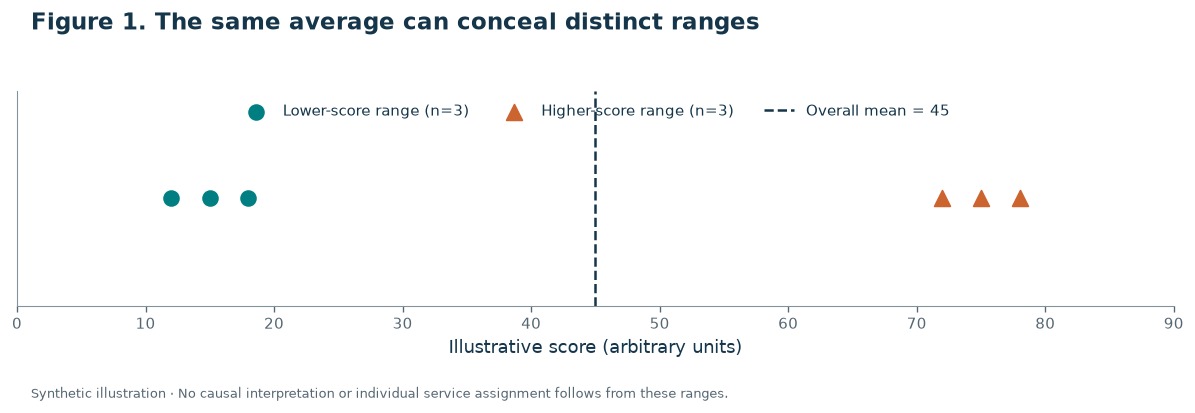

In [3]:
tiny=np.array([12,15,18,72,75,78])
tiny_summary=pd.DataFrame({'Illustrative group':['All six observations','Lower-score range','Higher-score range'],'n':[6,3,3],'Mean (arbitrary units)':[tiny.mean(),tiny[:3].mean(),tiny[3:].mean()]})
table(tiny_summary,'01_average_example','Table 1. One average can conceal two different ranges','Six fictional scores; the two ranges were defined for illustration, not learned by a model.',digits=1)
fig,ax=plt.subplots(figsize=(10.5,3.3))
ax.scatter(tiny[:3],np.zeros(3),c=TEAL,marker='o',s=80,label='Lower-score range (n=3)')
ax.scatter(tiny[3:],np.zeros(3),c=ORANGE,marker='^',s=90,label='Higher-score range (n=3)')
ax.axvline(tiny.mean(),color=NAVY,ls='--',lw=1.5,label='Overall mean = 45')
ax.set(xlabel='Illustrative score (arbitrary units)',yticks=[],xlim=(0,90),ylim=(-.6,.6));ax.legend(loc='upper center',ncol=3)
figure_done(fig,'01_beyond_the_mean','Figure 1. The same average can conceal distinct ranges','Synthetic illustration · No causal interpretation or individual service assignment follows from these ranges.')

The overall mean is 45, while the illustrative ranges average 15 and 75. The mean is numerically correct, but it does not describe either range well. Clustering offers a systematic way to explore similarity in many measured features. It does not establish why people differ.

## 2 | Meet the two synthetic datasets

The health cohort contains **1,200 fictional records** of people reported as having interrupted routine ART care. The customer cohort contains **1,500 fictional e-commerce records**. The generators encode four hidden simulation patterns, solely to demonstrate later that the number of generating patterns need not equal a diagnostic's preferred K. They are not model features.

Numeric feature windows are stated in their labels: missed appointments and orders cover 12 months; browsing sessions cover 30 days. Other fields describe the fictional record at assessment. Currency is represented in arbitrary currency units. This simulation does not reconstruct the Nigerian study or represent a real service population.

In [4]:
def make_health_data(n=1200, seed=42):
    r=np.random.default_rng(seed); z=r.choice(4,n,p=[.30,.27,.25,.18])
    age=np.choose(z,[r.normal(27,6,n),r.normal(39,9,n),r.normal(46,10,n),r.normal(33,8,n)]).clip(15,75)
    art=np.choose(z,[r.gamma(2,5,n),r.gamma(3.5,12,n),r.gamma(5,13,n),r.gamma(2.8,9,n)]).clip(1,180)
    refill=np.array([r.choice([1,2],p=[.7,.3]) if q==0 else r.choice([1,2,3],p=[.2,.6,.2]) if q==1 else r.choice([2,3,6],p=[.2,.5,.3]) if q==2 else r.choice([1,2,3],p=[.5,.4,.1]) for q in z])
    missed=np.choose(z,[r.poisson(3,n),r.poisson(2,n),r.poisson(1,n),r.poisson(4,n)]).clip(0,12)
    days=np.choose(z,[r.normal(75,18,n),r.normal(62,15,n),r.normal(48,12,n),r.normal(105,25,n)]).clip(29,240)
    dist=np.choose(z,[r.gamma(3,5,n),r.gamma(2,4,n),r.gamma(1.8,3,n),r.gamma(4,7,n)]).clip(.5,100)
    attempts=np.choose(z,[r.poisson(2,n),r.poisson(3,n),r.poisson(1,n),r.poisson(2,n)]).clip(0,10)
    d=pd.DataFrame({"age_years":age.round().astype(int),"months_on_art":art.round(1),
      "refill_interval_months":refill,"missed_appointments_12m":missed,
      "days_since_expected_contact":days.round().astype(int),"travel_distance_km":dist.round(1),
      "contact_attempts":attempts,"sex":r.choice(["Female","Male"],n,p=[.64,.36]),
      "region":r.choice(["North Central","North West","North East","South South","South West"],n),
      "facility_type":r.choice(["Primary","Secondary","Tertiary","Community"],n),
      "viral_load_documented":r.choice(["Yes","No"],n,p=[.55,.45]),
      "contact_channel":r.choice(["Phone","SMS","Community worker","Not documented"],n),
      "_simulation_pattern":z})
    for col,p in [("travel_distance_km",.08),("viral_load_documented",.12),("contact_channel",.07),("months_on_art",.03)]:
        d.loc[r.choice(d.index,int(p*n),replace=False),col]=np.nan
    return d

def make_ecommerce_data(n=1500, seed=43):
    r=np.random.default_rng(seed); z=r.choice(4,n,p=[.28,.26,.24,.22])
    orders=np.choose(z,[r.poisson(2,n),r.poisson(10,n),r.poisson(5,n),r.poisson(3,n)]).clip(0,40)
    aov=np.choose(z,[r.normal(35,12,n),r.normal(58,18,n),r.normal(110,28,n),r.normal(48,16,n)]).clip(5,300)
    discount=np.choose(z,[r.beta(2,2,n),r.beta(2,5,n),r.beta(1.5,5,n),r.beta(5,2,n)]).clip(0,1)
    returns=np.choose(z,[r.beta(1.5,10,n),r.beta(1.5,12,n),r.beta(2.5,8,n),r.beta(3,6,n)]).clip(0,1)
    recency=np.choose(z,[r.gamma(4,25,n),r.gamma(2,8,n),r.gamma(2.5,15,n),r.gamma(5,24,n)]).clip(1,365)
    sessions=np.choose(z,[r.poisson(3,n),r.poisson(12,n),r.poisson(7,n),r.poisson(5,n)]).clip(0,60)
    abandon=np.choose(z,[r.beta(4,3,n),r.beta(2,5,n),r.beta(3,4,n),r.beta(5,2,n)]).clip(0,1)
    d=pd.DataFrame({"orders_12m":orders,"avg_order_value":aov.round(2),"discount_share":discount.round(3),
      "return_rate":returns.round(3),"days_since_purchase":recency.round().astype(int),
      "sessions_30d":sessions,"cart_abandonment_rate":abandon.round(3),
      "category":r.choice(["Home","Fashion","Electronics","Beauty","Grocery"],n),
      "acquisition_channel":r.choice(["Organic","Paid search","Social","Email","Referral"],n),
      "device":r.choice(["Mobile","Desktop","Tablet"],n,p=[.65,.30,.05]),
      "loyalty_member":r.choice(["Yes","No"],n,p=[.38,.62]),"_simulation_pattern":z})
    for col,p in [("avg_order_value",.04),("return_rate",.06),("acquisition_channel",.03),("cart_abandonment_rate",.05)]:
        d.loc[r.choice(d.index,int(p*n),replace=False),col]=np.nan
    return d

health=make_health_data()
ecommerce=make_ecommerce_data()

for name,df in [('health',health),('ecommerce',ecommerce)]:
    df.drop(columns='_simulation_pattern').to_csv(OUT/'data'/f'synthetic_{name}_input.csv',index=False)
table(pd.DataFrame({'Dataset':['Synthetic health','Synthetic e-commerce'],'Records':[len(health),len(ecommerce)],'Observed attributes':[health.shape[1]-1,ecommerce.shape[1]-1],'Hidden patterns (not features)':[4,4]}),'02_dataset_overview','Table 2. Teaching data at a glance','Deterministic generators: health seed 42; e-commerce seed 43. No real patient or customer data.')
for name,df,fields in [('health',health,['age_years','months_on_art','days_since_expected_contact','travel_distance_km','viral_load_documented']),('ecommerce',ecommerce,['orders_12m','avg_order_value','days_since_purchase','return_rate','device'])]:
    table(df[fields].head().rename(columns=LABELS),f'03_{name}_preview',f'Table 3. {name.capitalize()} preview — first five fictional records','A preview only. Complete synthetic inputs are exported as CSV; missing values are shown as an em dash.')


Dataset,Records,Observed attributes,Hidden patterns (not features)
Synthetic health,"1,200",12,4
Synthetic e-commerce,"1,500",11,4


Age (years),ART duration (months),Days since expected contact,Travel distance (km),Viral load documented
60,63.20,43,8.60,Yes
52,49.70,84,6.70,Yes
25,23.40,110,27.50,No
34,32.20,74,11.60,Yes
25,7.10,68,5.80,Yes


Orders (12 months),Mean order value (currency units),Days since purchase,Return rate (0–1),Device
3,48.99,41,0.16,Mobile
2,48.59,190,0.14,Mobile
1,41.55,105,—,Desktop
1,47.01,101,—,Mobile
4,86.12,6,0.11,Mobile


## 3 | CHECK → CLEAN → VERIFY → ANALYZE

Before modelling, inspect the unit of analysis, distributions, missingness, duplicates and correlations. Do not delete every record with a missing value. In real data, missing documentation can reflect a recording or service process; it does not establish a person's motivation.

### Under the hood: structured data-quality audit

Each row in the following tables is one field. Percentages use all records in the corresponding dataset as the denominator. Numeric summaries use observed, nonmissing values. Direct identifiers are absent; hidden simulation labels are excluded from this audit and every model matrix.

In [5]:
def journal_audit(df,name):
    x=df.drop(columns='_simulation_pattern');N=len(x)
    quality=pd.DataFrame({'Attribute':[label(c) for c in x],'Type':['Numeric' if pd.api.types.is_numeric_dtype(x[c]) else 'Categorical' for c in x],'Observed n':[x[c].notna().sum() for c in x],'Missing n':[x[c].isna().sum() for c in x],'Missing (%)':[100*x[c].isna().mean() for c in x]})
    table(quality,f'04_{name}_quality',f'Table 4. {name.capitalize()} completeness and data types',f'Synthetic data; N={N:,}. Percent missing = missing n / N × 100. Duplicate complete rows: {x.duplicated().sum()}.',digits=1)
    rows=[]
    for c in x.select_dtypes(include=np.number):
        s=x[c].dropna();rows.append({'Attribute':label(c),'Observed n':len(s),'Mean':s.mean(),'SD':s.std(),'Median':s.median(),'Q1':s.quantile(.25),'Q3':s.quantile(.75)})
    table(pd.DataFrame(rows),f'05_{name}_descriptive',f'Table 5. {name.capitalize()} numeric characteristics','Observed values only; SD uses n−1. Quartiles describe the empirical distribution; no inferential intervals are estimated.')
    return quality
health_quality=journal_audit(health,'health');ecom_quality=journal_audit(ecommerce,'ecommerce')

Attribute,Type,Observed n,Missing n,Missing (%)
Age (years),Numeric,"1,200",0,0.0
ART duration (months),Numeric,"1,164",36,3.0
Refill interval (months),Numeric,"1,200",0,0.0
Missed appointments (12 months),Numeric,"1,200",0,0.0
Days since expected contact,Numeric,"1,200",0,0.0
Travel distance (km),Numeric,"1,104",96,8.0
Contact attempts (count),Numeric,"1,200",0,0.0
Sex,Categorical,"1,200",0,0.0
Region,Categorical,"1,200",0,0.0
Facility type,Categorical,"1,200",0,0.0


Attribute,Observed n,Mean,SD,Median,Q1,Q3
Age (years),"1,200",35.94,11.14,35.00,28.00,44.00
ART duration (months),"1,164",35.91,30.53,27.55,11.40,52.42
Refill interval (months),"1,200",2.16,1.33,2.00,1.00,3.00
Missed appointments (12 months),"1,200",2.44,1.92,2.00,1.00,4.00
Days since expected contact,"1,200",69.94,25.09,66.00,52.00,84.00
Travel distance (km),"1,104",13.06,11.43,9.45,4.80,17.90
Contact attempts (count),"1,200",1.99,1.58,2.00,1.00,3.00


Attribute,Type,Observed n,Missing n,Missing (%)
Orders (12 months),Numeric,"1,500",0,0.0
Mean order value (currency units),Numeric,"1,440",60,4.0
Discount share (0–1),Numeric,"1,500",0,0.0
Return rate (0–1),Numeric,"1,410",90,6.0
Days since purchase,Numeric,"1,500",0,0.0
Sessions (30 days),Numeric,"1,500",0,0.0
Cart abandonment (0–1),Numeric,"1,425",75,5.0
Product category,Categorical,"1,500",0,0.0
Acquisition channel,Categorical,"1,455",45,3.0
Device,Categorical,"1,500",0,0.0


Attribute,Observed n,Mean,SD,Median,Q1,Q3
Orders (12 months),"1,500",5.01,3.89,4.00,2.00,7.00
Mean order value (currency units),"1,440",62.83,34.32,54.15,38.19,78.47
Discount share (0–1),"1,500",0.43,0.25,0.39,0.22,0.64
Return rate (0–1),"1,410",0.19,0.14,0.16,0.09,0.27
Days since purchase,"1,500",66.69,56.58,52.00,20.00,103.25
Sessions (30 days),"1,500",6.83,4.33,6.00,3.00,10.00
Cart abandonment (0–1),"1,425",0.50,0.23,0.50,0.31,0.69


### Distributions, missingness and relationships

Look for skew, outliers and repeated information. Histogram axes retain the original units; proportions are not percentages unless labelled as such. Correlations use pairwise observed numeric values and describe association, not causation.

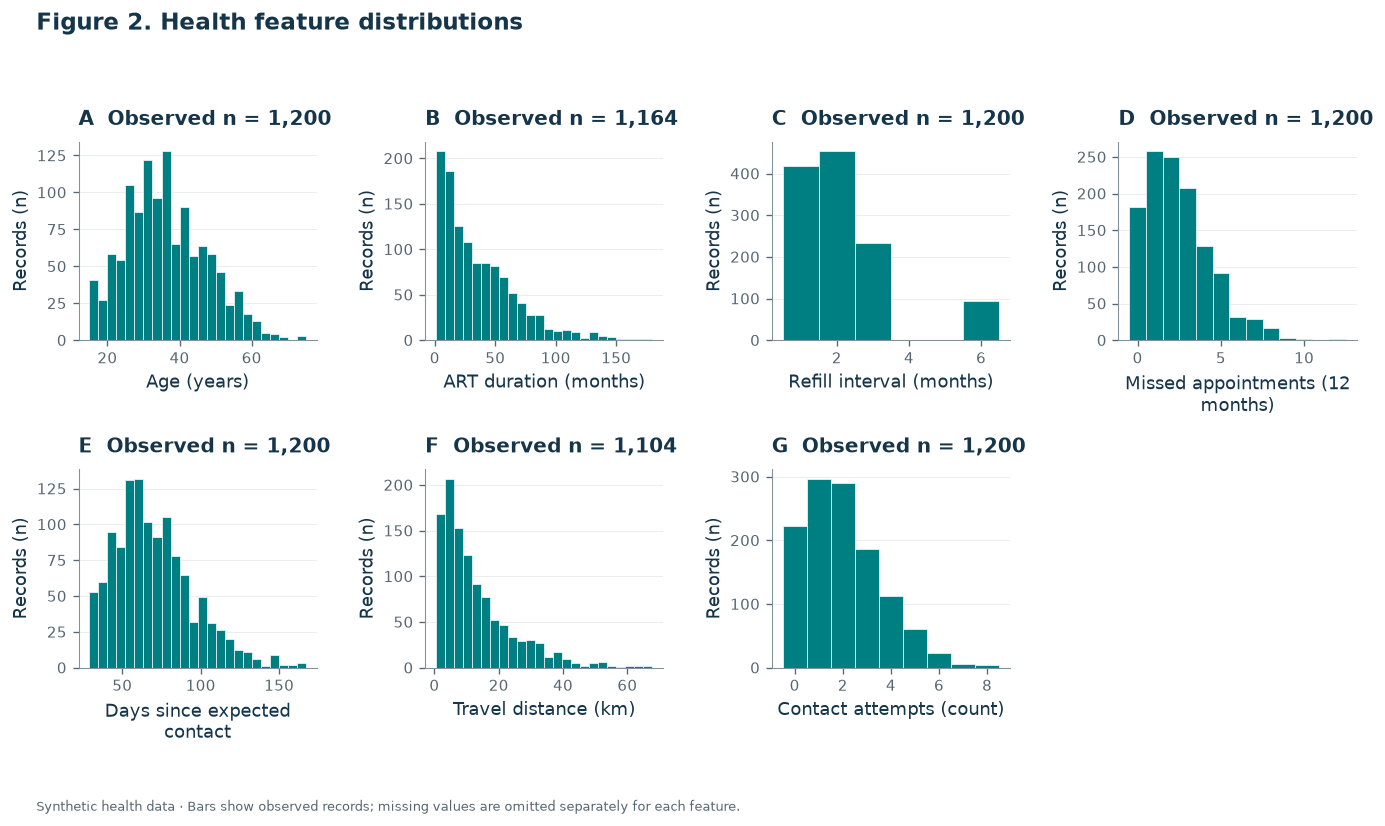

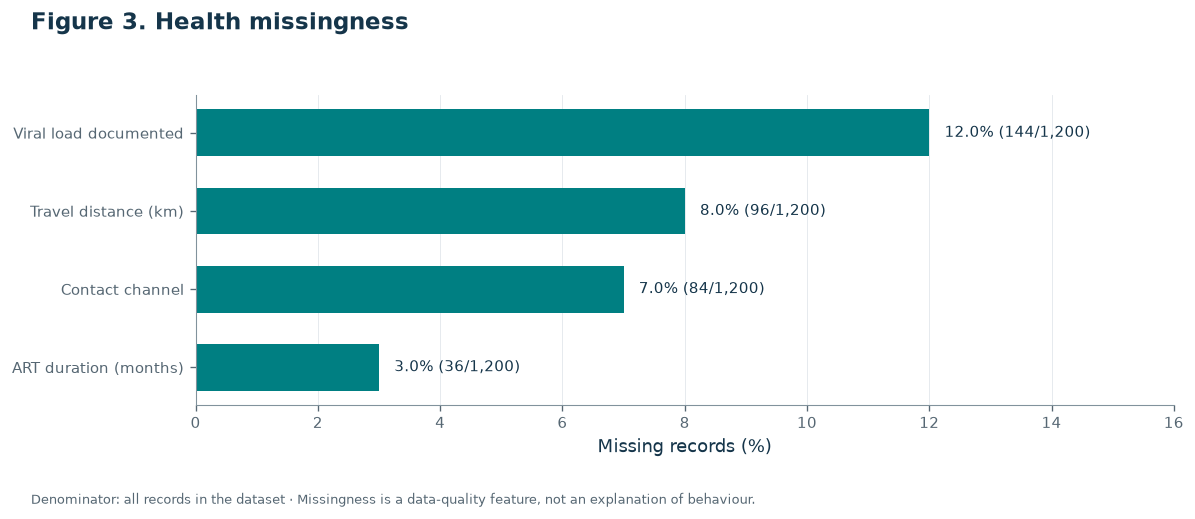

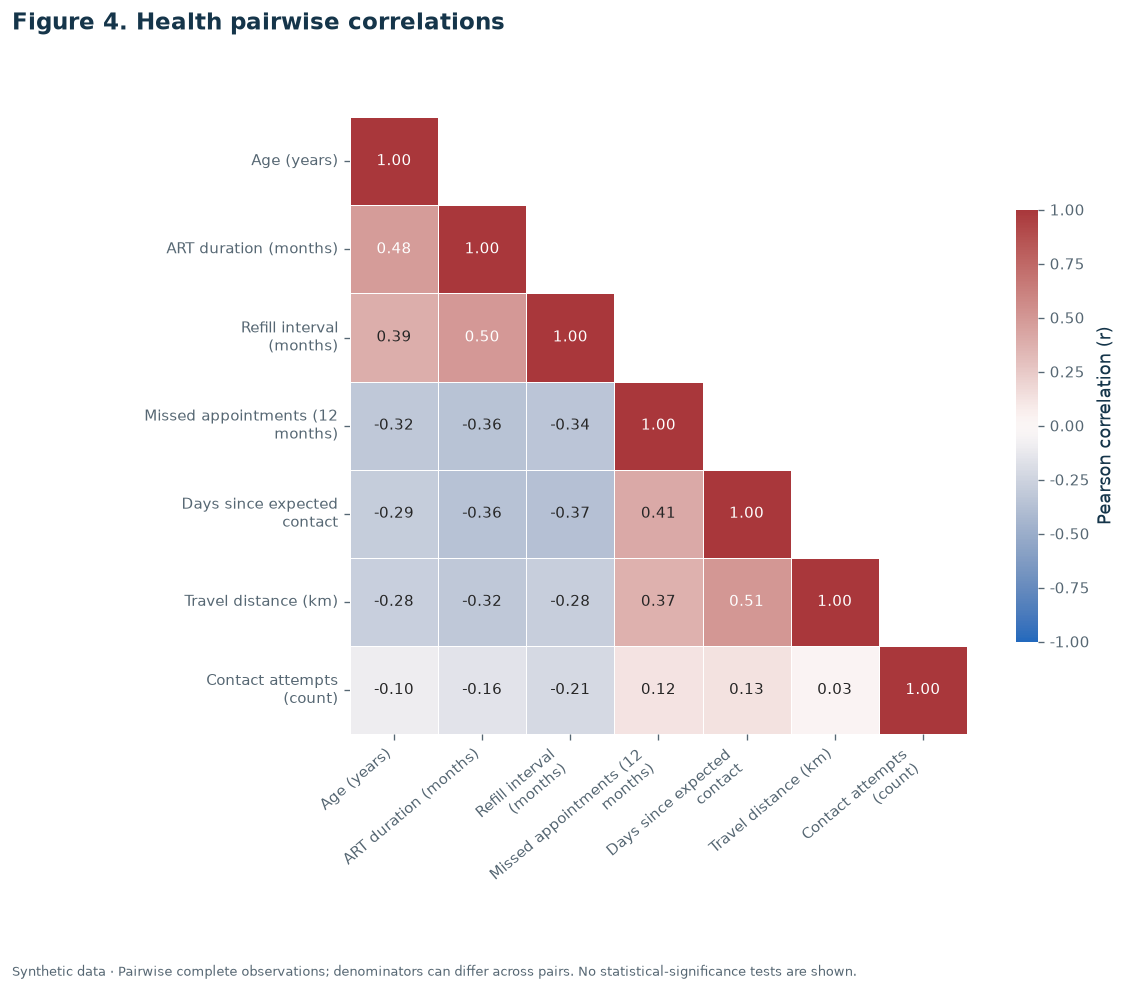

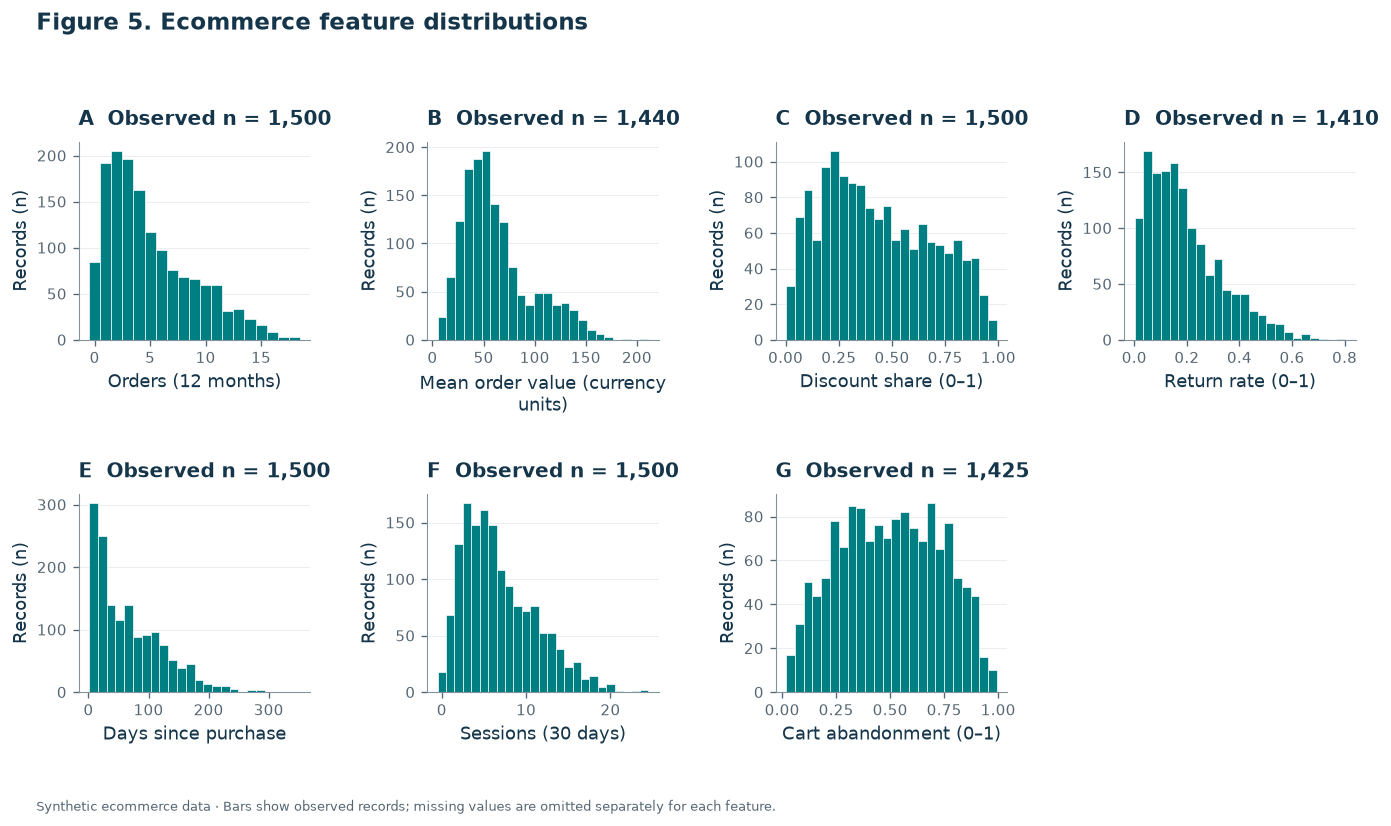

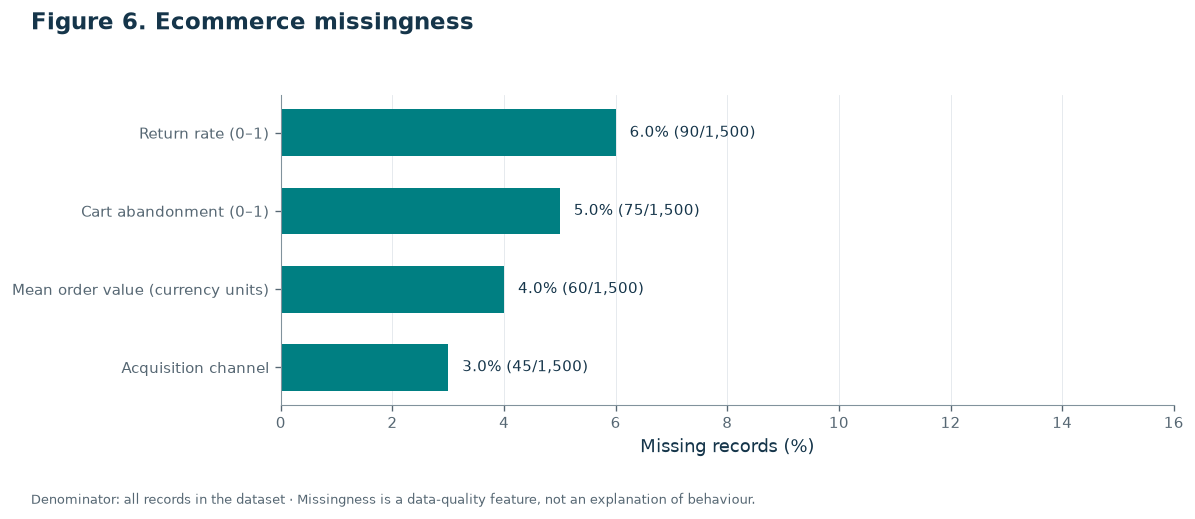

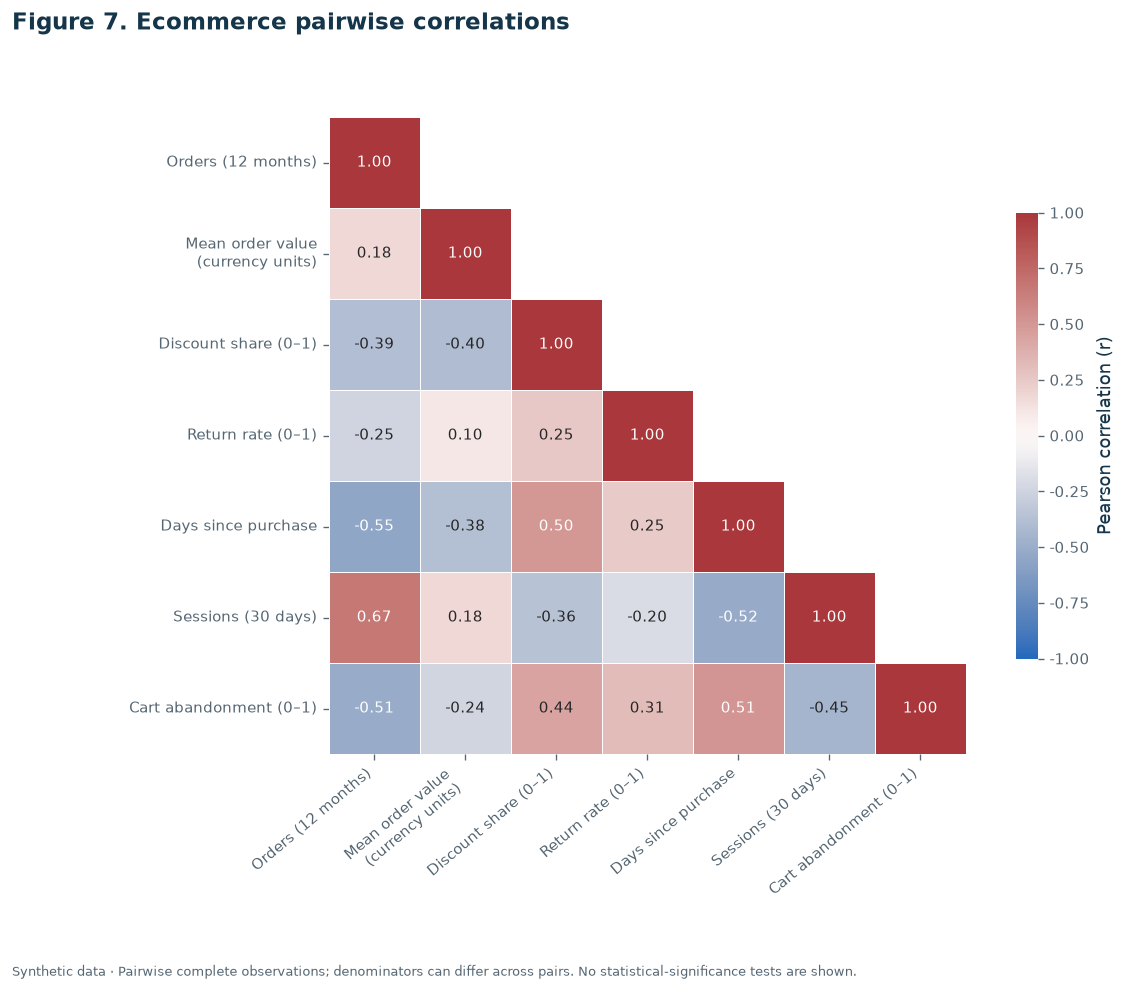

In [6]:
def journal_eda(df,name):
    x=df.drop(columns='_simulation_pattern');nums=x.select_dtypes(include=np.number)
    fig,axs=plt.subplots(2,4,figsize=(12,6.8));axs=axs.ravel()
    for j,c in enumerate(nums):
        ax=axs[j];s=nums[c].dropna()
        bins=np.arange(s.min()-.5,s.max()+1.5,1) if np.allclose(s,np.round(s)) and s.nunique()<=40 else 24
        ax.hist(s,bins=bins,color=TEAL,edgecolor='white',linewidth=.4)
        ax.set(xlabel=label(c),ylabel='Records (n)');ax.set_xlabel('\n'.join(textwrap.wrap(label(c),26)))
        panel(ax,chr(65+j),f'Observed n = {len(s):,}')
    for ax in axs[len(nums.columns):]: ax.set_visible(False)
    figure_done(fig,f'02_{name}_distributions',f'Figure 2. {name.capitalize()} feature distributions',f'Synthetic {name} data · Bars show observed records; missing values are omitted separately for each feature.')
    miss=x.isna().sum();miss=miss[miss>0].sort_values()
    fig,ax=plt.subplots(figsize=(10.5,4.2));y=np.arange(len(miss));pct=100*miss/len(x)
    ax.barh(y,pct,color=TEAL,height=.6);ax.set_yticks(y,[label(c) for c in miss.index]);ax.set(xlabel='Missing records (%)',xlim=(0,16))
    for j,(n,p) in enumerate(zip(miss,pct)):ax.text(p+.25,j,f'{p:.1f}% ({n:,}/{len(x):,})',va='center',fontsize=9)
    ax.grid(axis='x');figure_done(fig,f'03_{name}_missingness',f'Figure 3. {name.capitalize()} missingness','Denominator: all records in the dataset · Missingness is a data-quality feature, not an explanation of behaviour.')
    corr=nums.corr();corr.rename(index=LABELS,columns=LABELS).to_csv(OUT/'data'/f'{name}_correlations.csv')
    short=['\n'.join(textwrap.wrap(label(c),23)) for c in nums]
    fig,ax=plt.subplots(figsize=(10.5,8.2));mask=np.triu(np.ones_like(corr,dtype=bool),k=1)
    sns.heatmap(corr,mask=mask,ax=ax,cmap='vlag',vmin=-1,vmax=1,center=0,annot=True,fmt='.2f',square=True,linewidths=.6,cbar_kws={'label':'Pearson correlation (r)','shrink':.7},xticklabels=short,yticklabels=short,annot_kws={'size':9})
    ax.tick_params(axis='x',rotation=40);plt.setp(ax.get_xticklabels(),ha='right');ax.tick_params(axis='y',rotation=0)
    figure_done(fig,f'04_{name}_correlations',f'Figure 4. {name.capitalize()} pairwise correlations','Synthetic data · Pairwise complete observations; denominators can differ across pairs. No statistical-significance tests are shown.')
journal_eda(health,'health');journal_eda(ecommerce,'ecommerce')

### EDA questions to answer before modelling
- Which variables are skewed or have outliers?
- Which variables are correlated or duplicate similar information?
- Could missingness reflect a process such as incomplete documentation?
- Are identifiers or sensitive fields present? Remove direct identifiers; justify every feature.
- What real decision could a profile inform?
- Are units and observation windows comparable across records?

Do not include sensitive/demographic attributes automatically. They may be important for auditing fairness and coverage even when excluded from cluster construction.

## 4 | Prepare distances deliberately

The demonstration retains the original feature set and preprocessing so the scientific results remain comparable with the supplied notebook. **Sex, region and other categorical attributes remain included in this teaching model.** This is not a recommendation to include them automatically in an operational health model. Real applications require a justified feature policy, sensitivity comparisons and fairness review.

Numeric values receive median imputation and standardisation. Categories receive most-frequent imputation and one-hot encoding. Feature weights, cardinality and imputation affect the geometry. Nominal categories must not be treated as arbitrarily ordered integers. Mixed-type methods such as Gower distance with a suitable clustering method may be preferable for other questions.

In [7]:
def prepare(df):
    reference=df["_simulation_pattern"].copy()
    X=df.drop(columns=["_simulation_pattern"]).copy()
    num=X.select_dtypes(include=np.number).columns.tolist()
    cat=X.select_dtypes(exclude=np.number).columns.tolist()
    numeric=Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())])
    categorical=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                          ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
    prep=ColumnTransformer([("num",numeric,num),("cat",categorical,cat)],verbose_feature_names_out=False)
    arr=prep.fit_transform(X)
    Xt=pd.DataFrame(arr,columns=prep.get_feature_names_out(),index=X.index)
    return X,Xt,prep,reference,num,cat
health_raw,health_X,health_prep,health_ref,health_num,health_cat=prepare(health)
ecom_raw,ecom_X,ecom_prep,ecom_ref,ecom_num,ecom_cat=prepare(ecommerce)

assert not any('simulation' in c for c in health_X.columns)
assert not any('simulation' in c for c in ecom_X.columns)
assert np.isfinite(health_X.to_numpy()).all() and np.isfinite(ecom_X.to_numpy()).all()
table(pd.DataFrame({'Dataset':['Health','E-commerce'],'Numeric features':[len(health_num),len(ecom_num)],'Categorical features':[len(health_cat),len(ecom_cat)],'Encoded dimensions':[health_X.shape[1],ecom_X.shape[1]],'Retained records':[len(health_X),len(ecom_X)]}),'06_preprocessing','Table 6. Preprocessing preserves records and expands categorical features','Median imputation + StandardScaler for numeric fields; most-frequent imputation + one-hot encoding for categories. Simulation labels excluded.')


Dataset,Numeric features,Categorical features,Encoded dimensions,Retained records
Health,7,5,24,"1,200"
E-commerce,7,4,22,"1,500"


,Dataset,Numeric features,Categorical features,Encoded dimensions,Retained records
0,Health,7,5,24,1200
1,E-commerce,7,4,22,1500


## 5 | PCA: a projection, not a clustering verdict

PCA represents transformed features along directions of variance. It can simplify a display or reduce dimension, but may discard a low-variance feature that matters substantively. The cumulative curve tells you how much transformed variance is retained; the two-dimensional plot is a projection, not proof of group separation.

Primary clustering below uses the **full transformed feature space**. A separate optional comparison fits models in a PCA-reduced space retaining at least 90% of variance.

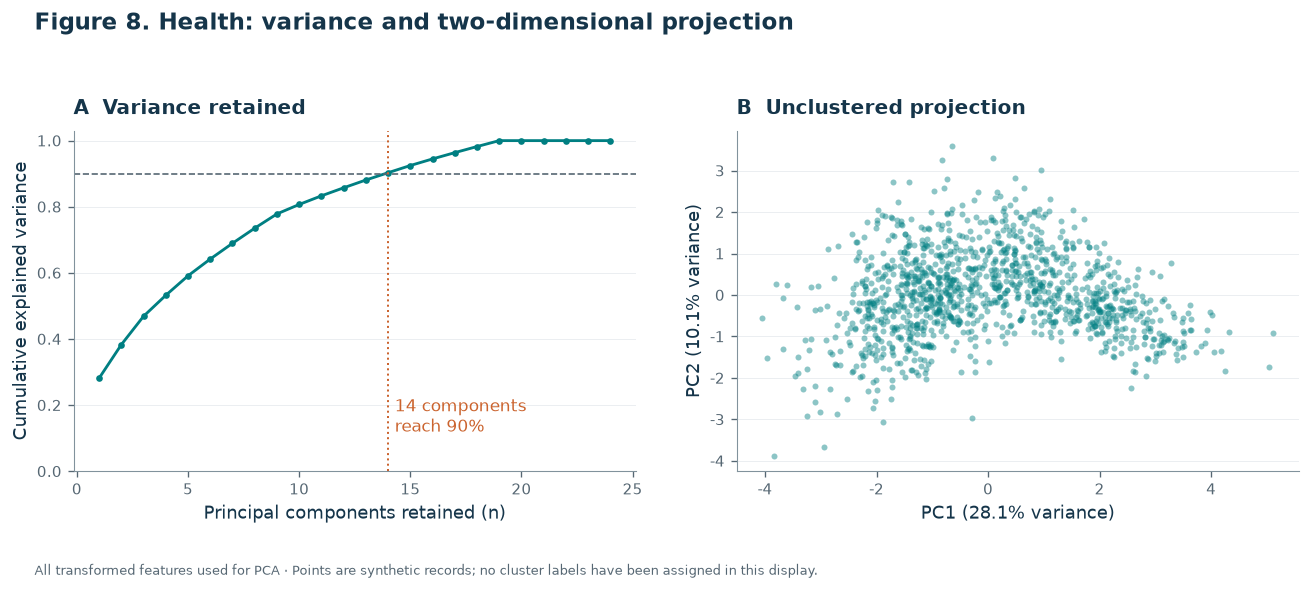

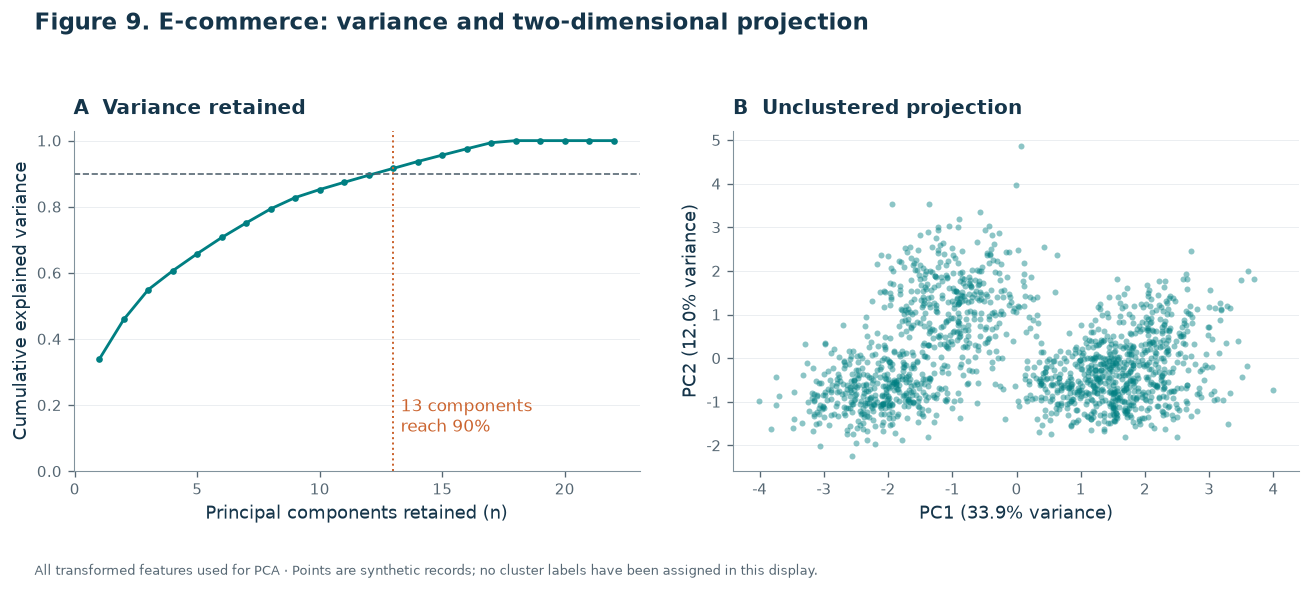

In [8]:
PCA_INFO={}
def pca_eda(X,title):
    p=PCA(random_state=RANDOM_STATE);scores=p.fit_transform(X);cum=np.cumsum(p.explained_variance_ratio_)
    n90=int(np.argmax(cum>=.90)+1) if np.any(cum>=.90) else len(cum)
    p2=PCA(n_components=2,random_state=RANDOM_STATE);s2=p2.fit_transform(X)
    PCA_INFO[title]={'variance':p2.explained_variance_ratio_.tolist(),'components_90pct':n90}
    pd.DataFrame({'component':np.arange(1,len(cum)+1),'variance_fraction':p.explained_variance_ratio_,'cumulative_fraction':cum}).to_csv(OUT/'data'/f'{title.lower()}_pca_variance.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(11.5,4.8))
    ax=axs[0];ax.plot(np.arange(1,len(cum)+1),cum,color=TEAL,marker='o',markersize=3)
    ax.axhline(.9,ls='--',color=GREY,lw=1);ax.axvline(n90,ls=':',color=ORANGE,lw=1.2)
    ax.text(n90+.3,.12,f'{n90} components\nreach 90%',color=ORANGE,fontsize=10)
    ax.set(xlabel='Principal components retained (n)',ylabel='Cumulative explained variance',ylim=(0,1.03));panel(ax,'A','Variance retained')
    axs[1].scatter(s2[:,0],s2[:,1],s=13,alpha=.45,c=TEAL,rasterized=True,linewidths=0)
    axs[1].set(xlabel=f'PC1 ({100*p2.explained_variance_ratio_[0]:.1f}% variance)',ylabel=f'PC2 ({100*p2.explained_variance_ratio_[1]:.1f}% variance)');panel(axs[1],'B','Unclustered projection')
    figure_done(fig,f'05_{title.lower()}_pca',f'Figure 5. {title}: variance and two-dimensional projection','All transformed features used for PCA · Points are synthetic records; no cluster labels have been assigned in this display.')
    return s2,n90
health_2d,health_n90=pca_eda(health_X,'Health');ecom_2d,ecom_n90=pca_eda(ecom_X,'E-commerce')

## 5. Select candidate K with silhouette analysis

Silhouette compares within-cluster similarity with similarity to the nearest alternative cluster. Scores closer to 1 generally indicate clearer separation, near 0 indicate overlap, and negative scores may indicate questionable assignments. It is a diagnostic, not an automatic answer: it often favours compact, well-separated groups and may undervalue useful clusters with irregular shapes or different densities. Consider cluster size, stability, domain interpretability, and consequences of errors too.

The scans use K = 2–8, a fixed initialisation seed and 20 starts. Silhouette is evaluated on a reproducible sample of up to 1,000 records, so the displayed diagnostic is not necessarily the all-record score. The first panel pair uses a shared vertical scale.

Dataset,K,Silhouette,Smallest cluster n,Largest cluster n
Health,2,0.180,536,664
Health,3,0.125,277,547
Health,4,0.110,207,392
Health,5,0.117,94,373
Health,6,0.108,94,314
Health,7,0.099,94,281
Health,8,0.091,94,278
E-commerce,2,0.249,750,750
E-commerce,3,0.212,358,740
E-commerce,4,0.174,303,443


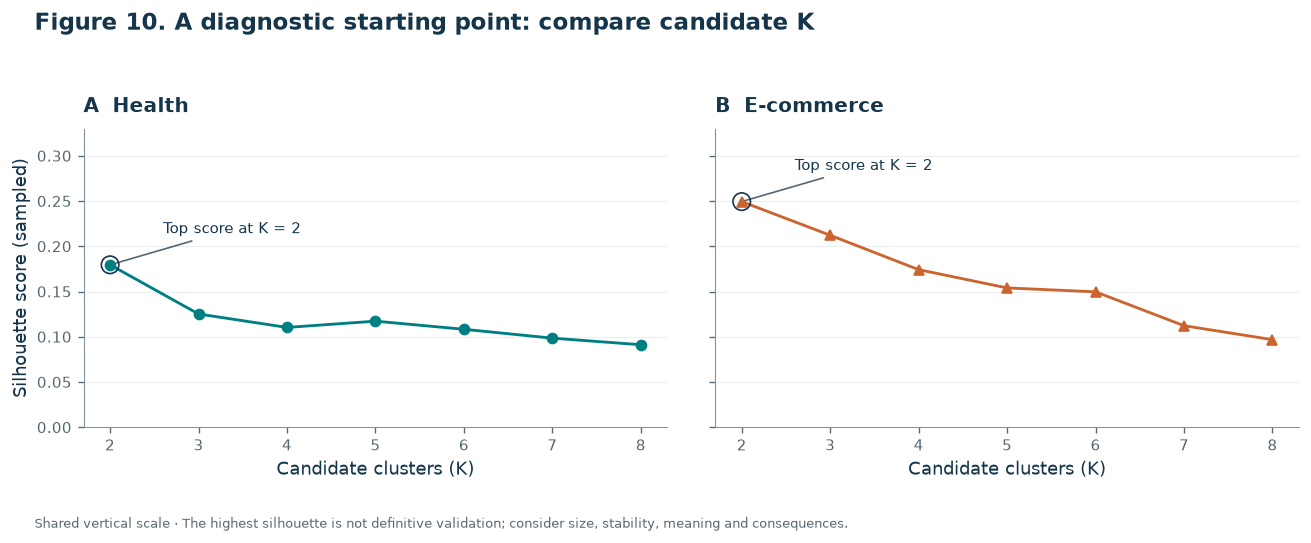

In [9]:
def scan_k(X,title,ks=range(2,9)):
    rows=[]
    for k in ks:
        lab=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=20).fit_predict(X)
        score=silhouette_score(X,lab,sample_size=min(1000,len(X)),random_state=RANDOM_STATE)
        sizes=pd.Series(lab).value_counts()
        rows.append({"K":k,"silhouette":score,"smallest_cluster_n":sizes.min(),"largest_cluster_n":sizes.max()})
    out=pd.DataFrame(rows)
    return out

health_scan=scan_k(health_X,'Health');ecom_scan=scan_k(ecom_X,'E-commerce')
scan_rows=[]
for name,scan in [('Health',health_scan),('E-commerce',ecom_scan)]:
    q=scan.copy();q.insert(0,'Dataset',name);scan_rows.append(q)
table(pd.concat(scan_rows,ignore_index=True).rename(columns={'silhouette':'Silhouette','smallest_cluster_n':'Smallest cluster n','largest_cluster_n':'Largest cluster n'}),'07_candidate_k','Table 7. Candidate K and cluster-size diagnostics','Silhouette: fixed sample of min(1,000, N); sizes: all fitted records. K is a candidate count, not an established service classification.',digits=3)
fig,axs=plt.subplots(1,2,figsize=(11.5,4.4),sharey=True)
for j,(name,scan) in enumerate([('Health',health_scan),('E-commerce',ecom_scan)]):
    ax=axs[j];ax.plot(scan.K,scan.silhouette,marker=MARKERS[j],color=PALETTE[j]);best=scan.loc[scan.silhouette.idxmax()]
    ax.scatter([best.K],[best.silhouette],s=110,facecolors='none',edgecolors=NAVY,zorder=5)
    ax.annotate(f'Top score at K = {int(best.K)}',xy=(best.K,best.silhouette),xytext=(best.K+.6,best.silhouette+.035),fontsize=9,arrowprops={'arrowstyle':'-','color':GREY})
    ax.set(xlabel='Candidate clusters (K)',xticks=range(2,9),ylim=(0,.33));panel(ax,chr(65+j),name)
axs[0].set_ylabel('Silhouette score (sampled)')
figure_done(fig,'06_candidate_k','Figure 6. A diagnostic starting point: compare candidate K','Shared vertical scale · The highest silhouette is not definitive validation; consider size, stability, meaning and consequences.')

### Optional comparison: retain 90% of variance

Keep candidate K fixed while comparing original transformed space with PCA-reduced space. Scores are calculated within their respective spaces; a larger score after reduction alone does not establish a substantively better model.

In [10]:
health_pca90=PCA(n_components=health_n90,random_state=RANDOM_STATE).fit_transform(health_X)
ecom_pca90=PCA(n_components=ecom_n90,random_state=RANDOM_STATE).fit_transform(ecom_X)
health_k_original=int(health_scan.loc[health_scan.silhouette.idxmax(),'K'])
ecom_k_original=int(ecom_scan.loc[ecom_scan.silhouette.idxmax(),'K'])
space_rows=[]
for name,original,reduced,k in [('Health',health_X,health_pca90,health_k_original),('E-commerce',ecom_X,ecom_pca90,ecom_k_original)]:
    for space,arr in [('Full transformed',original),('PCA ≥90% variance',reduced)]:
        labels=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=20).fit_predict(arr)
        space_rows.append({'Dataset':name,'Feature space':space,'Dimensions':arr.shape[1],'K':k,'Silhouette':silhouette_score(arr,labels,sample_size=min(1000,len(arr)),random_state=RANDOM_STATE)})
space_comparison=pd.DataFrame(space_rows)
table(space_comparison,'08_pca_comparison','Table 8. PCA changes the feature space being assessed','Same candidate K, seed and n_init; silhouette is measured in each fitted space. Primary models below remain in full transformed space.',digits=3)

Dataset,Feature space,Dimensions,K,Silhouette
Health,Full transformed,24,2,0.180
Health,PCA ≥90% variance,14,2,0.199
E-commerce,Full transformed,22,2,0.249
E-commerce,PCA ≥90% variance,13,2,0.273


,Dataset,Feature space,Dimensions,K,Silhouette
0,Health,Full transformed,24,2,0.179592
1,Health,PCA ≥90% variance,14,2,0.198915
2,E-commerce,Full transformed,22,2,0.249451
3,E-commerce,PCA ≥90% variance,13,2,0.272663


## 6. Fit K-means and agglomerative hierarchical clustering

K-means is often efficient for larger numeric datasets with compact, roughly spherical clusters. It requires K and is sensitive to scale, outliers, feature weighting, and initialisation. Agglomerative clustering builds nested groups and a dendrogram; Ward linkage is a common option for scaled numeric/Euclidean data, but hierarchical clustering can become expensive for large datasets.

Choose a candidate K by combining the silhouette scan, cluster sizes, domain interpretation, and stability. The code below uses the top silhouette K as a *starting point only*; change it if the resulting groups are not useful or robust.

In [11]:
health_k=int(health_scan.loc[health_scan.silhouette.idxmax(),"K"])
ecom_k=int(ecom_scan.loc[ecom_scan.silhouette.idxmax(),"K"])

def compare_methods(X,k,title):
    km=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=20)
    km_lab=km.fit_predict(X)
    hc=AgglomerativeClustering(n_clusters=k,linkage="ward")
    hc_lab=hc.fit_predict(X)
    scores=pd.DataFrame({"method":["K-means","Agglomerative (Ward)"],
       "silhouette":[silhouette_score(X,km_lab,sample_size=min(1000,len(X)),random_state=RANDOM_STATE),
                     silhouette_score(X,hc_lab,sample_size=min(1000,len(X)),random_state=RANDOM_STATE)]})

    return {"km":km,"km_labels":km_lab,"hc":hc,"hc_labels":hc_lab,"scores":scores}
health_models=compare_methods(health_X,health_k,"Health")
ecom_models=compare_methods(ecom_X,ecom_k,"E-commerce")
method_rows=[]
for name,k,m in [('Health',health_k,health_models),('E-commerce',ecom_k,ecom_models)]:
    q=m['scores'].copy();q.insert(0,'Dataset',name);q.insert(1,'Candidate K',k);method_rows.append(q)
table(pd.concat(method_rows,ignore_index=True).rename(columns={'method':'Method','silhouette':'Silhouette'}),'09_method_comparison','Table 9. Compare algorithms on the same feature space','Fixed sampled silhouette; algorithms fitted on all records. A different cluster number is not a diagnosis or a causal explanation.',digits=3)


Dataset,Candidate K,Method,Silhouette
Health,2,K-means,0.180
Health,2,Agglomerative (Ward),0.164
E-commerce,2,K-means,0.249
E-commerce,2,Agglomerative (Ward),0.246


,Dataset,Candidate K,Method,Silhouette
0,Health,2,K-means,0.179592
1,Health,2,Agglomerative (Ward),0.164165
2,E-commerce,2,K-means,0.249451
3,E-commerce,2,Agglomerative (Ward),0.246435


## 7. Dendrogram and cophenetic correlation

A dendrogram visualises the order and distance at which groups merge. For legibility, this dendrogram uses a random subset. The cophenetic correlation measures how closely dendrogram cophenetic distances preserve original pairwise distances. A higher value means the tree represents those distances more faithfully, but it does **not** prove that clusters are meaningful, stable, fair, or useful. Compare linkage choices and use other diagnostics.

The display below compresses the tree to 24 terminal branches for readability. Parenthesised leaf labels indicate aggregated observation counts, not record identifiers. Cophenetic correlation is still computed from the complete 250-record subset hierarchy.

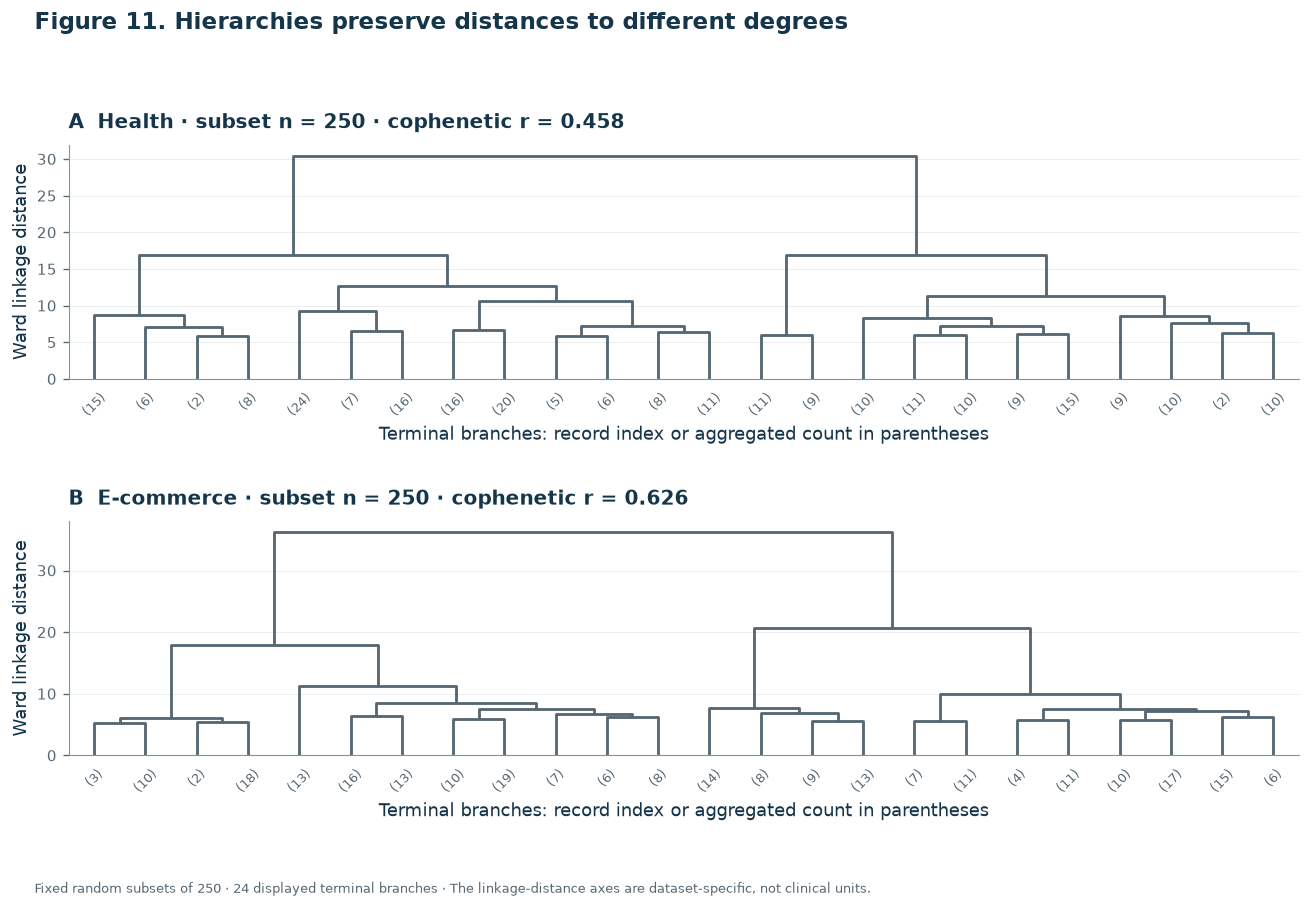

Dataset,Subset n,Cophenetic correlation
Health,250,0.458
E-commerce,250,0.626


,Dataset,Subset n,Cophenetic correlation
0,Health,250,0.457830
1,E-commerce,250,0.625552


In [12]:
def dendro_cophenetic(X,title,n=250):
    r=np.random.default_rng(RANDOM_STATE);ix=r.choice(len(X),size=min(n,len(X)),replace=False)
    Z=linkage(np.asarray(X)[ix],method='ward',metric='euclidean');c,_=cophenet(Z,pdist(np.asarray(X)[ix]))
    np.savez_compressed(OUT/'data'/f'{title.lower()}_hierarchy.npz',linkage=Z,subset_indices=ix)
    return Z,c
health_Z,health_coph=dendro_cophenetic(health_X,'Health');ecom_Z,ecom_coph=dendro_cophenetic(ecom_X,'E-commerce')
fig,axs=plt.subplots(2,1,figsize=(11.5,7.5))
for j,(name,Z,c) in enumerate([('Health',health_Z,health_coph),('E-commerce',ecom_Z,ecom_coph)]):
    dendrogram(Z,ax=axs[j],truncate_mode='lastp',p=24,show_leaf_counts=True,leaf_font_size=8,link_color_func=lambda _:GREY)
    axs[j].set(xlabel='Terminal branches: record index or aggregated count in parentheses',ylabel='Ward linkage distance');panel(axs[j],chr(65+j),f'{name} · subset n = 250 · cophenetic r = {c:.3f}')
figure_done(fig,'07_hierarchies','Figure 7. Hierarchies preserve distances to different degrees','Fixed random subsets of 250 · 24 displayed terminal branches · The linkage-distance axes are dataset-specific, not clinical units.')
table(pd.DataFrame({'Dataset':['Health','E-commerce'],'Subset n':[250,250],'Cophenetic correlation':[health_coph,ecom_coph]}),'10_cophenetic','Table 10. Fidelity of the subset hierarchies','Correlation of original pairwise distances with cophenetic distances; not cluster stability, fairness or service effectiveness.',digits=3)

## 8. PCA plots coloured by the cluster assignments

Models were fitted in the full transformed feature space; PCA is only used to project the results into two dimensions. Visible overlap in this projection does not necessarily mean that clusters overlap in the full feature space.

Both algorithms use the same axes and limits within a dataset. Cluster IDs and colours are **method-specific**: matching colours do not demonstrate that two methods assigned the same records. Markers and legend labels supplement colour; no confidence ellipses are implied.

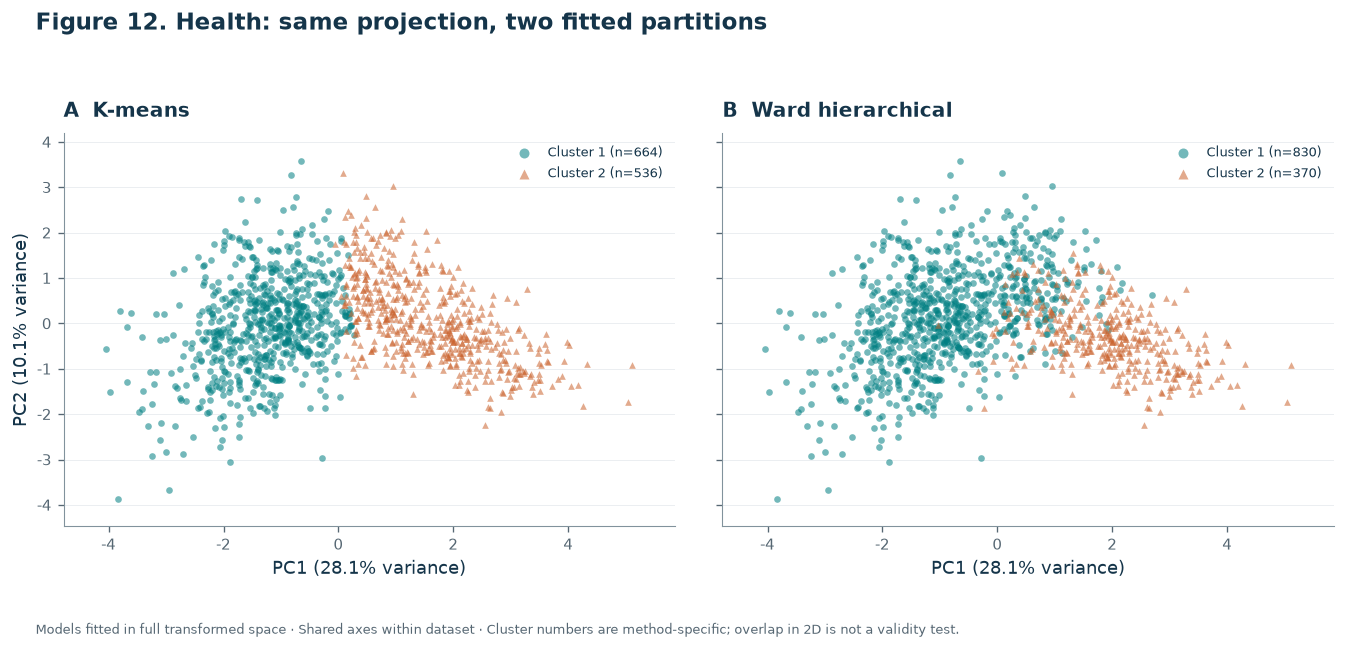

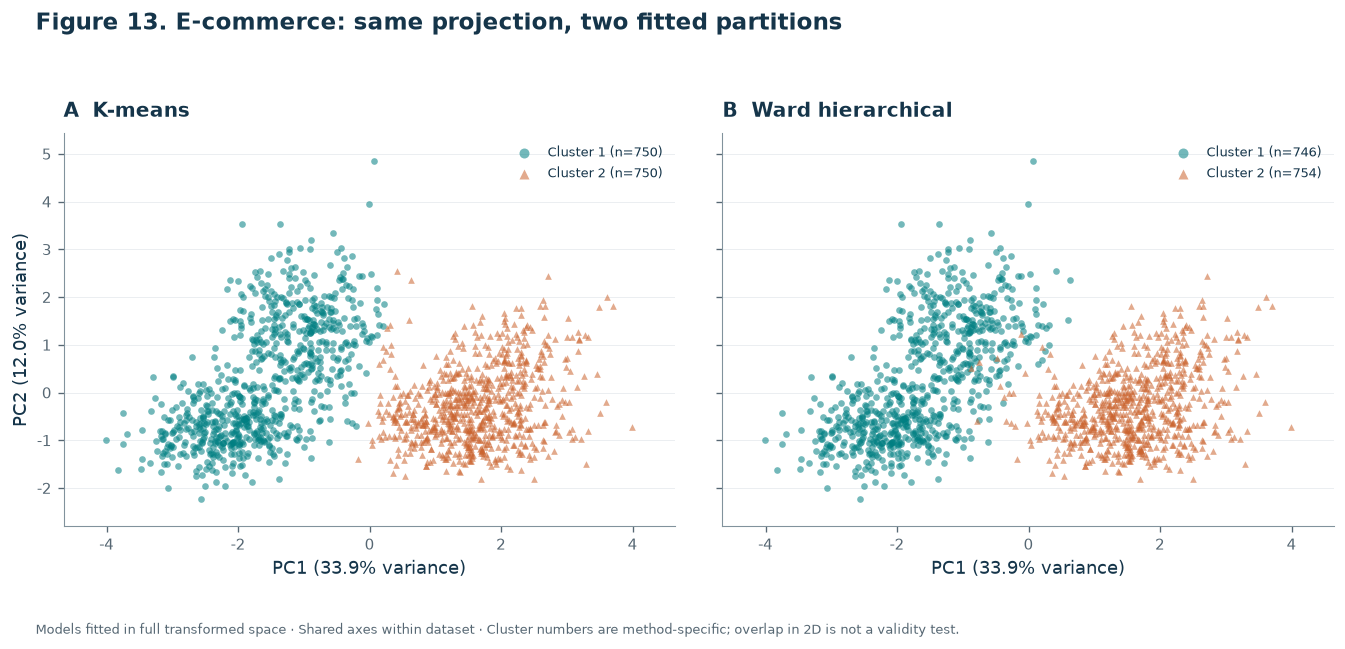

In [13]:
def paired_projection(scores,models,title):
    fig,axs=plt.subplots(1,2,figsize=(11.8,5.3),sharex=True,sharey=True)
    lower=scores.min(axis=0);upper=scores.max(axis=0);margin=(upper-lower)*.08
    var=PCA_INFO[title]['variance']
    for j,(key,name) in enumerate([('km_labels','K-means'),('hc_labels','Ward hierarchical')]):
        labels=models[key]
        for k in sorted(np.unique(labels)):
            mask=labels==k
            axs[j].scatter(scores[mask,0],scores[mask,1],s=16,alpha=.55,color=PALETTE[k],marker=MARKERS[k],linewidths=0,rasterized=True,label=f'Cluster {k+1} (n={mask.sum():,})')
        axs[j].set(xlabel=f'PC1 ({var[0]*100:.1f}% variance)',xlim=(lower[0]-margin[0],upper[0]+margin[0]),ylim=(lower[1]-margin[1],upper[1]+margin[1]));panel(axs[j],chr(65+j),name)
        axs[j].legend(loc='upper right',markerscale=1.5,fontsize=8)
    axs[0].set_ylabel(f'PC2 ({var[1]*100:.1f}% variance)')
    figure_done(fig,f'08_{title.lower()}_cluster_projection',f'Figure 8. {title}: same projection, two fitted partitions','Models fitted in full transformed space · Shared axes within dataset · Cluster numbers are method-specific; overlap in 2D is not a validity test.')
    pd.DataFrame({'PC1':scores[:,0],'PC2':scores[:,1],'cluster_kmeans':models['km_labels'],'cluster_hierarchical':models['hc_labels']}).to_csv(OUT/'data'/f'{title.lower()}_projection_assignments.csv',index=False)
paired_projection(health_2d,health_models,'Health');paired_projection(ecom_2d,ecom_models,'E-commerce')

## 9. Profile clusters in the original variables

Cluster IDs (0, 1, 2...) have no intrinsic meaning. Return to original features and describe numeric medians/means and categorical proportions. Use neutral descriptions grounded in observed data. In health, avoid labels that blame patients (such as “non-compliant”); prefer descriptions such as “shorter treatment duration with more missed appointments.” A profile is a hypothesis for further investigation, not an explanation of an individual's motives.

The following tables retain means and medians in original units for **both algorithms**. Numeric summaries use observed values; they are not summaries of imputed measurements. Categorical tables include a **Missing** level and use all records in each cluster as the denominator, so documentation gaps remain visible.

In [14]:
PROFILE_MEDIANS={}
def journal_profile(raw,labels,num_cols,cat_cols,dataset,method):
    d=raw.drop(columns='_simulation_pattern').copy();d['cluster']=np.asarray(labels);ks=sorted(d.cluster.unique());N=d.groupby('cluster').size()
    prefix=dataset.lower().replace('-','')+'_'+method.lower().replace(' ','_')
    table(pd.DataFrame({'Cluster':[f'Cluster {k+1}' for k in ks],'Records n':[N[k] for k in ks],'Share (%)':[100*N[k]/len(d) for k in ks]}),f'11_{prefix}_sizes',f'Table 11. {dataset} / {method}: cluster sizes',f'Synthetic N={len(d):,}; algorithm-specific labels.',digits=1)
    rows=[]
    for c in num_cols:
        row={'Attribute (original units)':label(c)}
        for k in ks:
            s=d.loc[d.cluster==k,c].dropna();row[f'C{k+1} observed n']=len(s);row[f'C{k+1} mean']=s.mean();row[f'C{k+1} median']=s.median()
        rows.append(row)
    table(pd.DataFrame(rows),f'12_{prefix}_numeric',f'Table 12. {dataset} / {method}: observed numeric profiles','C1 = Cluster 1, etc. Observed n is the nonmissing denominator for that attribute and cluster; original units are retained.')
    cats=[];tidy=[]
    for c in cat_cols:
        values=d[c].fillna('Missing');levels=sorted(values.unique())
        for level in levels:
            row={'Attribute':label(c),'Level':level}
            for k in ks:
                n=int(((values==level)&(d.cluster==k)).sum());p=100*n/N[k]
                row[f'Cluster {k+1}: n (%)']=f'{n:,} ({p:.1f}%)'
                tidy.append({'attribute':c,'level':level,'cluster':int(k),'n':n,'denominator':int(N[k]),'percent':p})
            cats.append(row)
    table(pd.DataFrame(cats),f'13_{prefix}_categorical',f'Table 13. {dataset} / {method}: categorical profiles','n (%) among ALL records in that cluster; Missing is included as a level. Percentages within each attribute and cluster sum to 100%, subject to rounding.')
    pd.DataFrame(tidy).to_csv(OUT/'data'/f'{prefix}_categorical_denominators.csv',index=False)
    med=d.groupby('cluster')[num_cols].median().T
    PROFILE_MEDIANS[(dataset,method)]=med
for name,raw,models,nums,cats in [('Health',health,health_models,health_num,health_cat),('E-commerce',ecommerce,ecom_models,ecom_num,ecom_cat)]:
    for key,method in [('km_labels','K-means'),('hc_labels','Ward')]: journal_profile(raw,models[key],nums,cats,name,method)


Cluster,Records n,Share (%)
Cluster 1,664,55.3
Cluster 2,536,44.7


Attribute (original units),C1 observed n,C1 mean,C1 median,C2 observed n,C2 mean,C2 median
Age (years),664,29.54,29.00,536,43.86,44.00
ART duration (months),646,17.16,13.50,518,59.29,53.85
Refill interval (months),664,1.49,1.00,536,2.99,3.00
Missed appointments (12 months),664,3.34,3.00,536,1.33,1.00
Days since expected contact,664,83.15,80.00,536,53.59,53.00
Travel distance (km),602,18.83,16.20,502,6.15,5.40
Contact attempts (count),664,2.17,2.00,536,1.77,1.50


Attribute,Level,Cluster 1: n (%),Cluster 2: n (%)
Sex,Female,432 (65.1%),346 (64.6%)
Sex,Male,232 (34.9%),190 (35.4%)
Region,North Central,151 (22.7%),91 (17.0%)
Region,North East,117 (17.6%),114 (21.3%)
Region,North West,123 (18.5%),102 (19.0%)
Region,South South,133 (20.0%),120 (22.4%)
Region,South West,140 (21.1%),109 (20.3%)
Facility type,Community,167 (25.2%),151 (28.2%)
Facility type,Primary,168 (25.3%),114 (21.3%)
Facility type,Secondary,177 (26.7%),119 (22.2%)


Cluster,Records n,Share (%)
Cluster 1,830,69.2
Cluster 2,370,30.8


Attribute (original units),C1 observed n,C1 mean,C1 median,C2 observed n,C2 mean,C2 median
Age (years),830,31.50,31.00,370,45.91,46.00
ART duration (months),806,23.03,17.05,358,64.89,58.45
Refill interval (months),830,1.63,2.00,370,3.35,3.00
Missed appointments (12 months),830,2.99,3.00,370,1.21,1.00
Days since expected contact,830,77.59,75.00,370,52.79,51.50
Travel distance (km),760,16.14,12.90,344,6.26,5.40
Contact attempts (count),830,2.37,2.00,370,1.15,1.00


...

Attribute (original units),C1 observed n,C1 mean,C1 median,C2 observed n,C2 mean,C2 median
Orders (12 months),750,7.68,7.00,750,2.35,2.00
Mean order value (currency units),726,83.32,76.28,714,41.99,40.34
Discount share (0–1),750,0.27,0.24,750,0.60,0.63
Return rate (0–1),703,0.16,0.14,707,0.22,0.19
Days since purchase,750,25.02,20.00,750,108.36,103.00
Sessions (30 days),750,9.69,9.00,750,3.97,4.00
Cart abandonment (0–1),699,0.34,0.33,726,0.64,0.67


Attribute,Level,Cluster 1: n (%),Cluster 2: n (%)
Product category,Beauty,158 (21.1%),124 (16.5%)
Product category,Electronics,162 (21.6%),149 (19.9%)
Product category,Fashion,144 (19.2%),156 (20.8%)
Product category,Grocery,133 (17.7%),158 (21.1%)
Product category,Home,153 (20.4%),163 (21.7%)
Acquisition channel,Email,144 (19.2%),146 (19.5%)
Acquisition channel,Missing,21 (2.8%),24 (3.2%)
Acquisition channel,Organic,135 (18.0%),143 (19.1%)
Acquisition channel,Paid search,171 (22.8%),143 (19.1%)
Acquisition channel,Referral,138 (18.4%),160 (21.3%)


Cluster,Records n,Share (%)
Cluster 1,746,49.7
Cluster 2,754,50.3


Attribute (original units),C1 observed n,C1 mean,C1 median,C2 observed n,C2 mean,C2 median
Orders (12 months),746,7.68,7.00,754,2.38,2.00
Mean order value (currency units),724,83.80,77.07,716,41.63,40.34
Discount share (0–1),746,0.27,0.24,754,0.60,0.63
Return rate (0–1),701,0.16,0.14,709,0.22,0.19
Days since purchase,746,25.30,20.00,754,107.64,102.50
Sessions (30 days),746,9.71,9.00,754,3.98,4.00
Cart abandonment (0–1),694,0.35,0.33,731,0.64,0.67


Attribute,Level,Cluster 1: n (%),Cluster 2: n (%)
Product category,Beauty,154 (20.6%),128 (17.0%)
Product category,Electronics,161 (21.6%),150 (19.9%)
Product category,Fashion,144 (19.3%),156 (20.7%)
Product category,Grocery,131 (17.6%),160 (21.2%)
Product category,Home,156 (20.9%),160 (21.2%)
Acquisition channel,Email,146 (19.6%),144 (19.1%)
Acquisition channel,Missing,21 (2.8%),24 (3.2%)
Acquisition channel,Organic,131 (17.6%),147 (19.5%)
Acquisition channel,Paid search,172 (23.1%),142 (18.8%)
Acquisition channel,Referral,137 (18.4%),161 (21.4%)


### Read profile contrasts without losing the original units

Cells below print each cluster's observed median in the feature's original units. Colour is a separate comparison aid: **(cluster median − overall observed median) / overall observed sample SD**. The fixed −2.5 to +2.5 colour scale is shared; extreme colours are clipped, while printed medians retain their values. This is a descriptive standardised contrast, not a confidence interval or effect estimate.

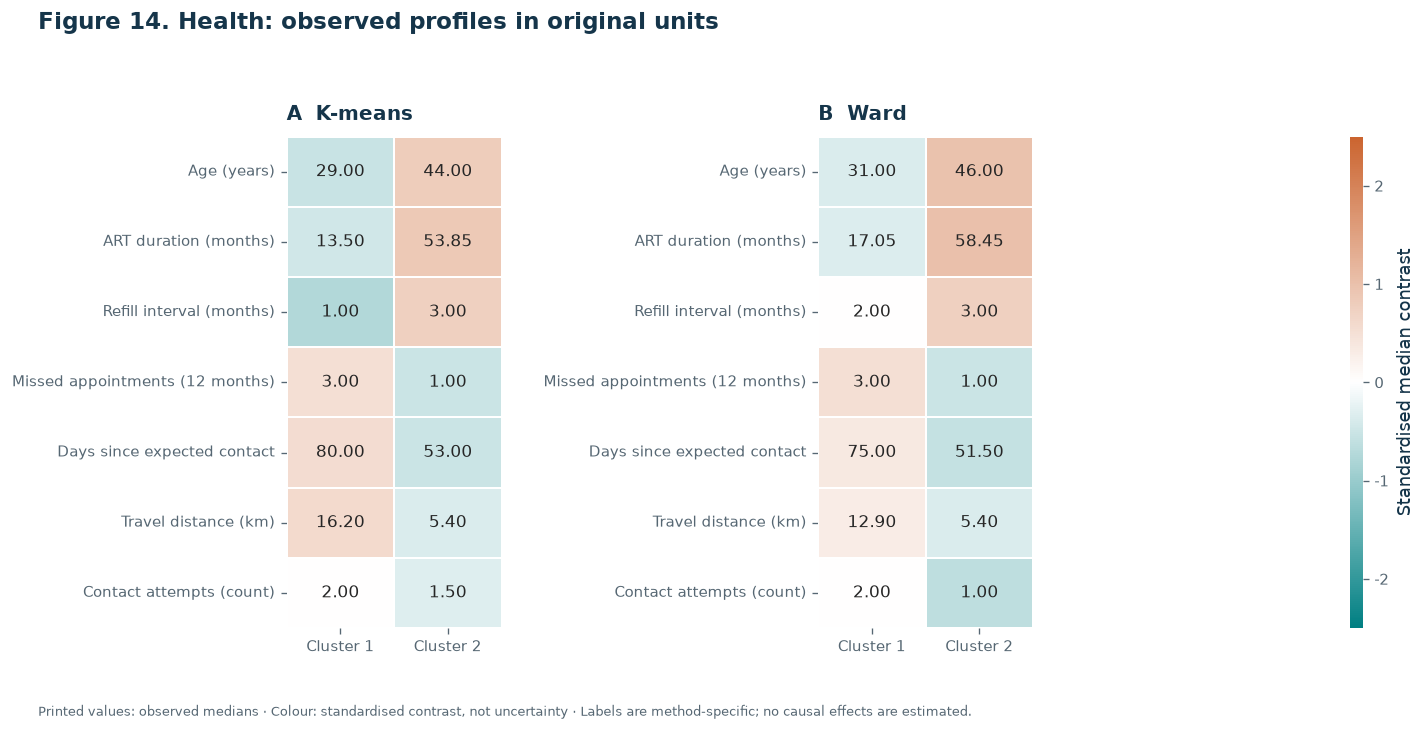

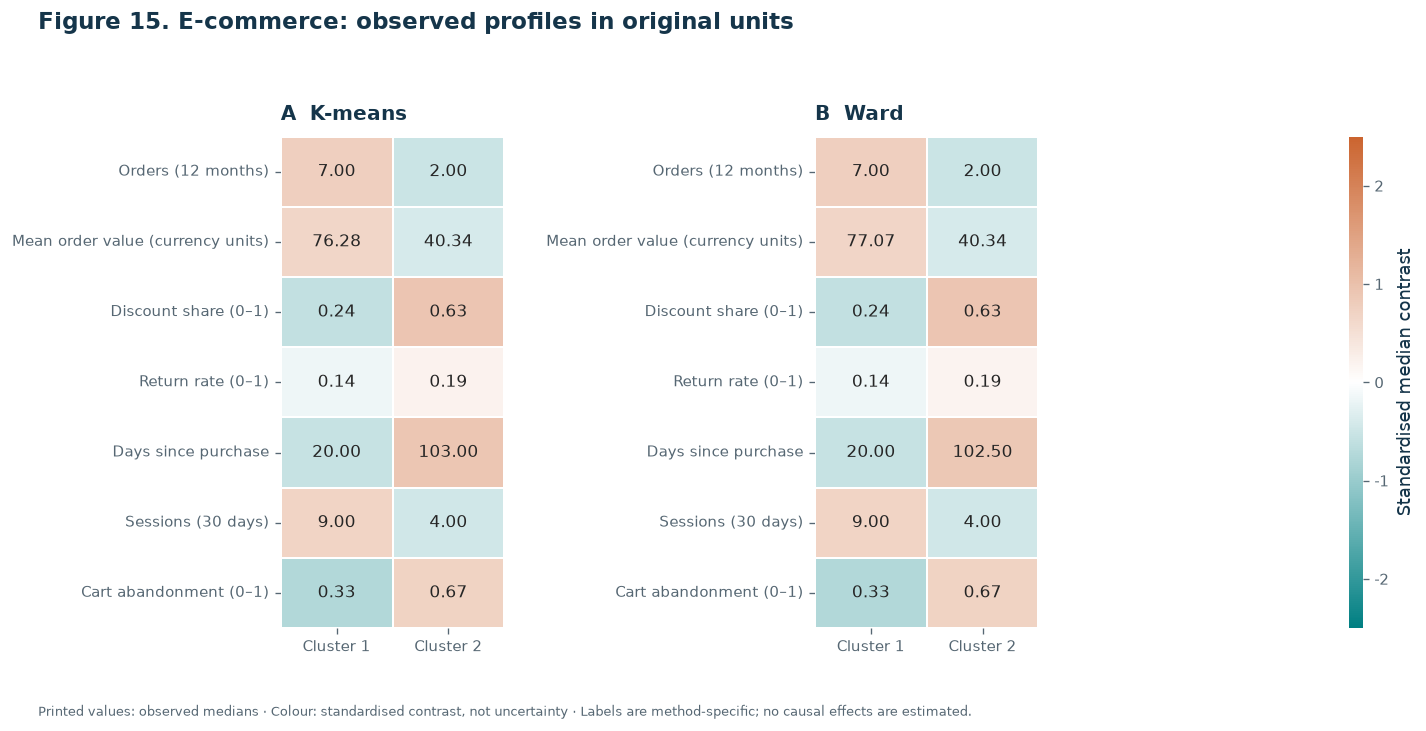

In [15]:
from matplotlib.colors import LinearSegmentedColormap
profile_cmap=LinearSegmentedColormap.from_list('profile',[TEAL,'#FFFFFF',ORANGE])
for name,raw,cols in [('Health',health,health_num),('E-commerce',ecommerce,ecom_num)]:
    fig,axs=plt.subplots(1,3,figsize=(12.5,6),gridspec_kw={'width_ratios':[1,1,.06]})
    for j,method in enumerate(['K-means','Ward']):
        med=PROFILE_MEDIANS[(name,method)];contrast=med.sub(raw[cols].median(),axis=0).div(raw[cols].std(),axis=0)
        ann=med.map(lambda v:f'{v:.2f}')
        sns.heatmap(contrast,ax=axs[j],cmap=profile_cmap,vmin=-2.5,vmax=2.5,center=0,annot=ann,fmt='',linewidths=1,annot_kws={'size':10},xticklabels=[f'Cluster {k+1}' for k in med.columns],yticklabels=[label(c) for c in cols],cbar=j==1,cbar_ax=axs[2],cbar_kws={'label':'Standardised median contrast'})
        axs[j].set(xlabel='',ylabel='');axs[j].tick_params(axis='x',rotation=0);axs[j].tick_params(axis='y',rotation=0);panel(axs[j],chr(65+j),method)
    figure_done(fig,f'09_{name.lower()}_profile_medians',f'Figure 9. {name}: observed profiles in original units','Printed values: observed medians · Colour: standardised contrast, not uncertainty · Labels are method-specific; no causal effects are estimated.')

## 10. Stability check and synthetic-only ground-truth demonstration

A useful cluster solution should not be an artefact of one sample or random initialisation. This simple subsampling check compares K-means partitions on overlapping observations using adjusted Rand index (ARI). It is an introductory diagnostic, not a full stability analysis.

Because these data were simulated, we can also compare to the hidden simulation pattern. This is possible only because we generated the data; real unsupervised learning has no known “true” labels. Never use `_simulation_pattern` as a feature.

Median pairwise subsample ARI: 0.984 | range: 0.924 - 1.0
Median pairwise subsample ARI: 1.0 | range: 0.996 - 1.0
Synthetic-only ARI; teaching diagnostic, not a real-world performance claim
Health K-means: 0.382
E-commerce K-means: 0.476


Dataset,Pairwise comparisons,Median ARI,Minimum ARI,Maximum ARI,ARI vs hidden patterns
Health,28,0.984,0.924,1.000,0.382
E-commerce,28,1.000,0.996,1.000,0.476


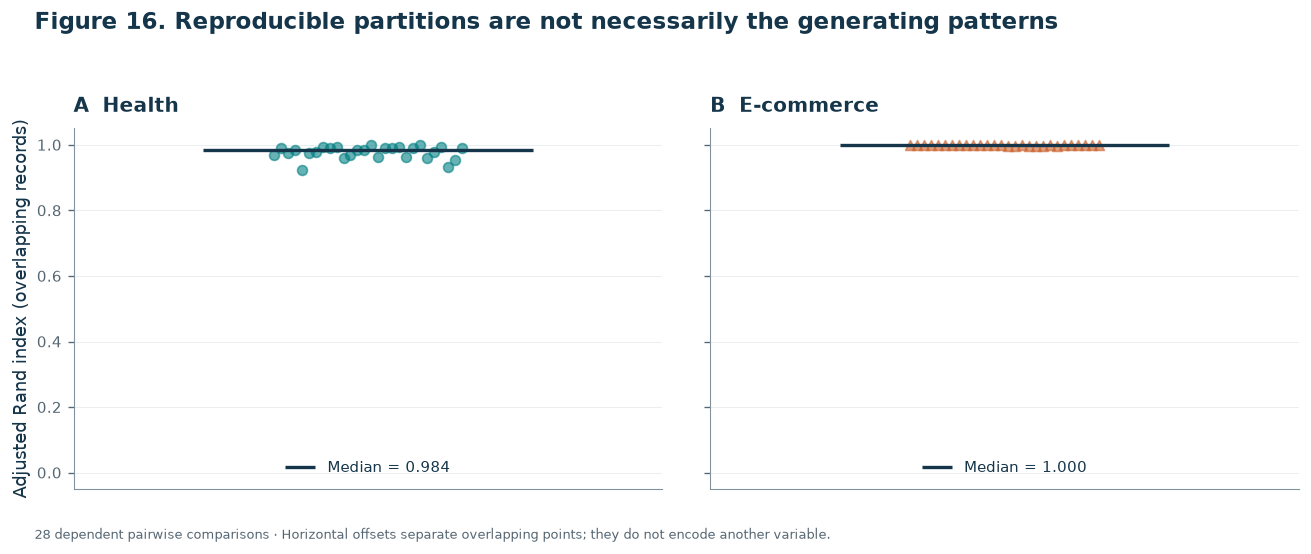

In [16]:
def stability(X,k,repeats=8,fraction=.8):
    r=np.random.default_rng(RANDOM_STATE); runs=[]
    for _ in range(repeats):
        ix=np.sort(r.choice(len(X),int(fraction*len(X)),replace=False))
        lab=KMeans(n_clusters=k,n_init=20,random_state=int(r.integers(1,999999))).fit_predict(np.asarray(X)[ix])
        runs.append((ix,lab))
    vals=[]
    for i in range(len(runs)):
        for j in range(i+1,len(runs)):
            a,la=runs[i]; b,lb=runs[j]
            common,ia,ib=np.intersect1d(a,b,return_indices=True)
            if len(common)>10: vals.append(adjusted_rand_score(la[ia],lb[ib]))
    print("Median pairwise subsample ARI:",round(float(np.median(vals)),3),
          "| range:",round(float(np.min(vals)),3),"-",round(float(np.max(vals)),3))
    return vals
health_stability=stability(health_X,health_k)
ecom_stability=stability(ecom_X,ecom_k)
print("Synthetic-only ARI; teaching diagnostic, not a real-world performance claim")
print("Health K-means:",round(adjusted_rand_score(health_ref,health_models["km_labels"]),3))
print("E-commerce K-means:",round(adjusted_rand_score(ecom_ref,ecom_models["km_labels"]),3))
stability_summary=pd.DataFrame([{'Dataset':name,'Pairwise comparisons':len(vals),'Median ARI':np.median(vals),'Minimum ARI':np.min(vals),'Maximum ARI':np.max(vals),'ARI vs hidden patterns':adjusted_rand_score(ref,models['km_labels'])} for name,vals,ref,models in [('Health',health_stability,health_ref,health_models),('E-commerce',ecom_stability,ecom_ref,ecom_models)]])
table(stability_summary,'14_stability','Table 14. Stability and simulation-pattern agreement answer different questions','Eight 80% subsamples; 28 overlapping pairs. Comparisons are dependent and do not form an inferential sample or confidence interval.',digits=3)
fig,axs=plt.subplots(1,2,figsize=(11.5,4.5),sharey=True)
for j,(name,vals) in enumerate([('Health',health_stability),('E-commerce',ecom_stability)]):
    xs=np.linspace(-.16,.16,len(vals));axs[j].scatter(xs,vals,c=PALETTE[j],marker=MARKERS[j],s=35,alpha=.6)
    axs[j].hlines(np.median(vals),-.28,.28,color=NAVY,lw=2,label=f'Median = {np.median(vals):.3f}')
    axs[j].set(xticks=[],xlim=(-.5,.5),ylim=(-.05,1.05));panel(axs[j],chr(65+j),name);axs[j].legend(loc='lower center')
axs[0].set_ylabel('Adjusted Rand index (overlapping records)')
figure_done(fig,'10_subsample_stability','Figure 10. Reproducible partitions are not necessarily the generating patterns','28 dependent pairwise comparisons · Horizontal offsets separate overlapping points; they do not encode another variable.')

The fitted K = 2 solutions are highly stable across these subsamples, but their agreement with the four hidden generating patterns is much lower. Stability, geometric separation and recovery of a simulation mechanism are different questions. None establishes a real person's needs.

## 6 | Experiment: change K while holding the data fixed

The complete static comparison below changes **only K**. Data, preprocessing, random seed and 20 starts stay fixed. Change `TRY_K` to an integer from 2 to 8, rerun this cell and compare silhouette, group sizes and synthetic-label agreement. The original fitted models remain unchanged.

In [17]:
TRY_K=4
assert isinstance(TRY_K,int) and 2<=TRY_K<=8,'Choose an integer from 2 to 8.'
experiment=[]
for k in sorted(set([health_k,TRY_K])):
    labs=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=20).fit_predict(health_X);sizes=pd.Series(labs).value_counts()
    experiment.append({'K':k,'Silhouette':silhouette_score(health_X,labs,sample_size=min(1000,len(health_X)),random_state=RANDOM_STATE),'Smallest cluster n':sizes.min(),'Largest cluster n':sizes.max(),'ARI vs hidden patterns':adjusted_rand_score(health_ref,labs)})
table(pd.DataFrame(experiment),'15_k_experiment','Table 15. Health sensitivity to the chosen K','Only K changes. Hidden-pattern agreement is available because this is a simulation; it is not a real-world validation target.',digits=3)

K,Silhouette,Smallest cluster n,Largest cluster n,ARI vs hidden patterns
2,0.180,536,664,0.382
4,0.110,207,392,0.538


,K,Silhouette,Smallest cluster n,Largest cluster n,ARI vs hidden patterns
0,2,0.179592,536,664,0.381944
1,4,0.110382,207,392,0.538197


## 11. When should you avoid K-means?

Be cautious when clusters are irregularly shaped, have very different densities or sizes, data contain substantial outliers, variables are mostly categorical, results change sharply with scaling or K, or cluster labels cannot be interpreted or linked to a legitimate decision.

Potential alternatives:
- **Agglomerative hierarchical clustering:** nested structure and dendrogram exploration; can be computationally expensive.
- **DBSCAN/HDBSCAN:** irregular dense groups and noise detection; parameter selection and varying densities can be challenging.
- **K-medoids with Gower distance:** often useful for mixed numeric/categorical data.
- **Gaussian mixture models:** probabilistic membership under distributional assumptions.
- **Latent class analysis:** designed for categorical indicators.
- **No clustering:** descriptive analysis, survival analysis, rule-based pathways, or supervised prediction may better answer the question.

Choose methods based on the data, question, and consequences of errors—not popularity.

## 7 | Connect to published evidence

**11,589 records · 313 USAID/PEPFAR-supported HIV clinics · six reported profiles.**

[Onovo, Kalaiwo and Obanubi's published Nigerian HIV study](https://www.longdom.org/open-access/aggregating-loss-to-followup-behavior-in-people-living-with-hiv-on-art-a-cluster-analysis-using-unsupervised-machine-learning-algo-1102545.html) used agglomerative hierarchical clustering to describe records reported as lost to follow-up. This is contextual evidence, not a replication of that patient dataset. The synthetic notebook's K = 2 candidates and the published study's six profiles are distinct results.

Profiles can suggest questions about treatment-continuity support, customer journeys or financial-service needs. A responsible route is **describe → investigate with service users and frontline teams → co-design options → offer support based on assessed needs and preferences → evaluate outcomes and equity**.

Clustering does not establish causes, automatically predict future outcomes or demonstrate which intervention works. Use a suitable predictive design for prediction and credible causal evaluation for intervention effects. The original supplied notebook's related One-Stop Shop discussion is preserved in the source archive; it did not test cluster-specific interventions.

## 8 | Reproducible results you can keep

The final cell exports both synthetic assignment datasets, a numerical summary, package versions, figure/table captions and a ZIP. Figures use fixed physical dimensions and embedded vector text in PDF; SVG text remains editable. Dense scatter points are rasterised within vector containers for manageable file sizes. PNGs are 300 dpi. Print-ready table pages avoid splitting rows across a page.

In Colab, open the Files panel, refresh it, then download `EvidenceLab_07_Journal_Outputs.zip`. The data are synthetic; keep the provenance notes and figure captions when reusing an export.

In [18]:
health_out=health.drop(columns=["_simulation_pattern"]).copy()
health_out["cluster_kmeans"]=health_models["km_labels"]
health_out["cluster_hierarchical"]=health_models["hc_labels"]
ecom_out=ecommerce.drop(columns=["_simulation_pattern"]).copy()
ecom_out["cluster_kmeans"]=ecom_models["km_labels"]
ecom_out["cluster_hierarchical"]=ecom_models["hc_labels"]
health_out.to_csv(OUT/"data"/"synthetic_health_cluster_assignments.csv",index=False)
ecom_out.to_csv(OUT/"data"/"synthetic_ecommerce_cluster_assignments.csv",index=False)

import importlib.metadata,platform,zipfile
summary={'seed':RANDOM_STATE,'health':{'rows':len(health),'features':health_X.shape[1],'candidate_k':health_k,'components_90pct':health_n90,'km_silhouette':float(health_models['scores'].iloc[0].silhouette),'ward_silhouette':float(health_models['scores'].iloc[1].silhouette),'cophenetic':float(health_coph),'median_stability_ari':float(np.median(health_stability)),'hidden_pattern_ari':float(adjusted_rand_score(health_ref,health_models['km_labels']))},'ecommerce':{'rows':len(ecommerce),'features':ecom_X.shape[1],'candidate_k':ecom_k,'components_90pct':ecom_n90,'km_silhouette':float(ecom_models['scores'].iloc[0].silhouette),'ward_silhouette':float(ecom_models['scores'].iloc[1].silhouette),'cophenetic':float(ecom_coph),'median_stability_ari':float(np.median(ecom_stability)),'hidden_pattern_ari':float(adjusted_rand_score(ecom_ref,ecom_models['km_labels']))}}
assert len(health_out)==1200 and len(ecom_out)==1500
assert sum(pd.Series(health_models['km_labels']).value_counts())==1200
assert not any('simulation' in c for c in health_X.columns) and not any('simulation' in c for c in ecom_X.columns)
for p in (OUT/'data').glob('*_categorical_denominators.csv'):
    q=pd.read_csv(p);assert np.allclose(q.groupby(['attribute','cluster']).percent.sum(),100)
(OUT/'numerical_summary.json').write_text(json.dumps(summary,indent=2))
(OUT/'environment.json').write_text(json.dumps({'python':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn']}},indent=2))
(OUT/'captions.json').write_text(json.dumps({'figures':FIGURES,'tables':TABLES},indent=2))
zip_path=Path('EvidenceLab_07_Journal_Outputs.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file():z.write(p,str(p))
print(f'Complete: {len(FIGURES)} figure sets, {len(TABLES)} formatted tables and synthetic exports. Download {zip_path.name}.')
print('Scientific checks passed. All data are synthetic; no clinical or commercial intervention effect was estimated.')


Complete: 16 figure sets, 27 formatted tables and synthetic exports. Download EvidenceLab_07_Journal_Outputs.zip.
Scientific checks passed. All data are synthetic; no clinical or commercial intervention effect was estimated.


## Five takeaways

1. A correct population average can conceal different measured patterns.
2. Preprocessing and feature choices shape distance-based clusters.
3. PCA, silhouette, cophenetic correlation and stability answer different diagnostic questions.
4. Return to original units and state the denominator; keep missing documentation visible.
5. Profiles suggest hypotheses for co-design and evaluation, not causes or fixed individual identities.

### Try it next

Which conclusions survive a justified change in K, feature weighting or treatment of missingness? What additional evidence would be needed before changing a service?

### Sources

- [scikit-learn: clustering methods and silhouette](https://scikit-learn.org/stable/modules/clustering.html).
- [scikit-learn: principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca).
- [SciPy: cophenetic correlation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.cophenet.html).
- [Published Nigerian HIV cluster analysis](https://www.longdom.org/open-access/aggregating-loss-to-followup-behavior-in-people-living-with-hiv-on-art-a-cluster-analysis-using-unsupervised-machine-learning-algo-1102545.html).

**EvidenceLab | See it. Understand it. Run it.**  
Dr. Amobi Andrew Onovo, PhD, MPH  
*Better data. Healthier people. A fairer world.*